# Static Sim 

Loading Native Julia AC-Capable Surrogates... (This only happens once)
Successfully loaded Native Julia LUTs!

 TRANSIENT BATCH EVALUATION: 300 CIRCUITS (31-STAGE RING OSCILLATOR)
Compiled Custom DC, AC, and Transient Simulator Successfully!

>>> Running 300-Batch Transient Solves on 20 Julia Threads (Gear Method)...
Julia 300-Circuit Transient Total Time: 62.244 s
    Saved fresh Julia results to: C:\Users\mohamed\Desktop\ML\CAD_projects\Netlists\GF_180nm_tech_work\project\New_Sim_tests\Allah_help_me2\Allah_Save_me\New folder\system\Testing\Spice_vs_Julia_Benchmarking\julia_ring31_cache_300.jld2

>>> Running LTspice baseline (Sequential)...
    LTspice progress: 50/300 circuits done...
    LTspice progress: 100/300 circuits done...
    LTspice progress: 150/300 circuits done...
    LTspice progress: 200/300 circuits done...
    LTspice progress: 250/300 circuits done...
    LTspice progress: 300/300 circuits done...
LTspice Total Time: 516.608 s
    Saved fresh LTspice results to: C:\

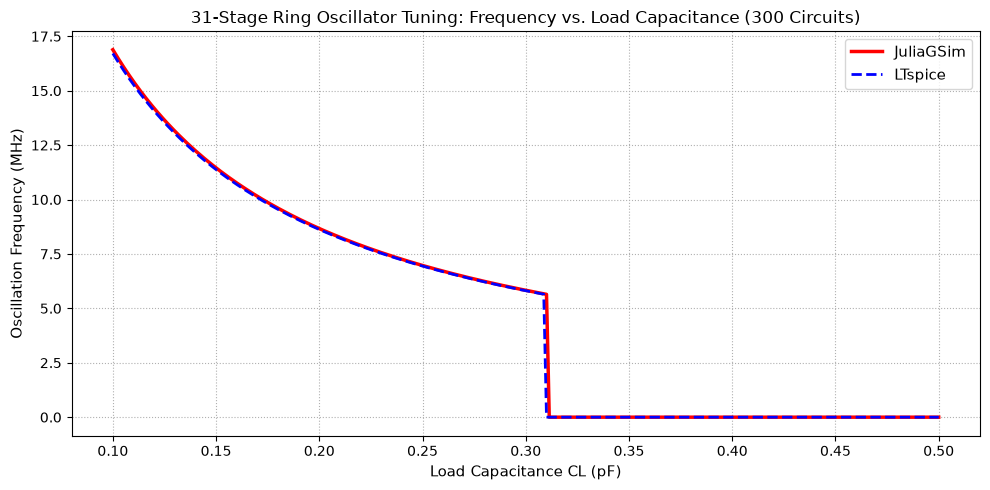


 WAVEFORM PLOTS: TOP 20 CIRCUITS WITH HIGHEST FREQUENCY MISMATCH
 (3 SEPARATE FIGURES PER CIRCUIT: V1, V15, V31 -> TOTAL 60 FIGURES)

 Worst Case #1 | Circuit 1 | CL = 0.100 pF | Freq Err = 1.03 %
 JuliaGSim Freq: 16.88 MHz | LTspice Freq: 16.71 MHz


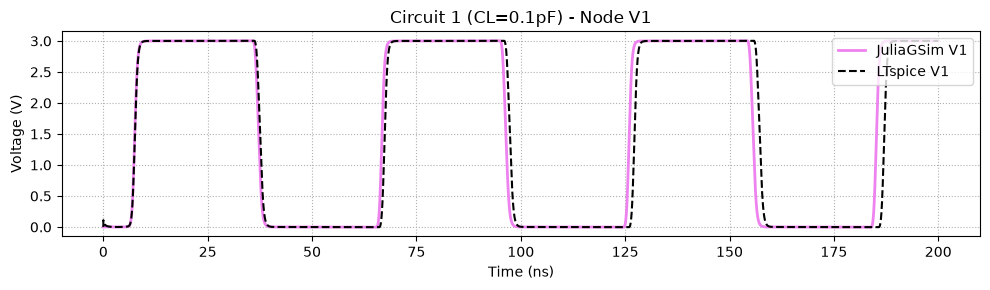

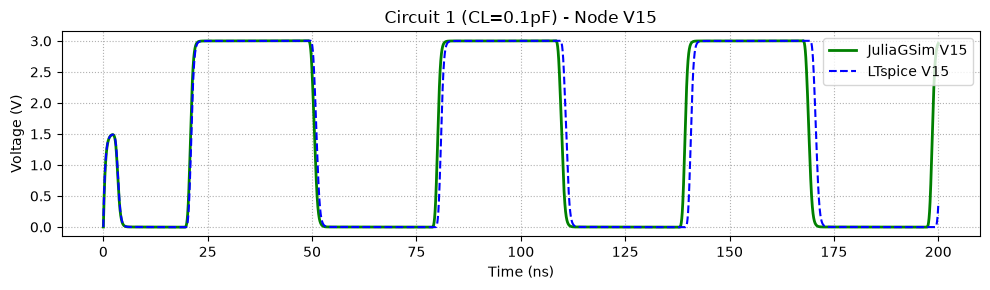

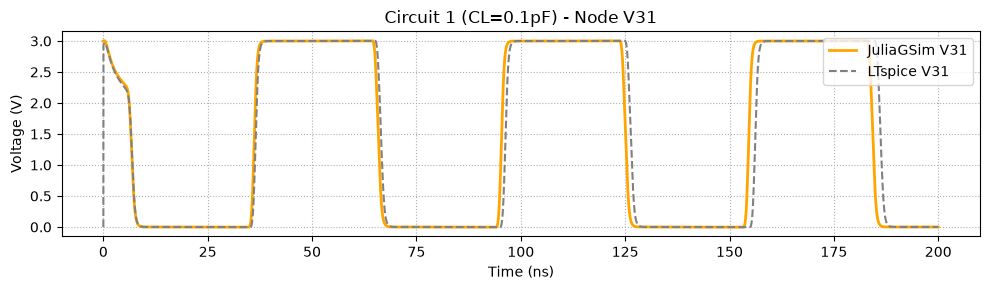

------------------------------------------------------------
 Worst Case #2 | Circuit 2 | CL = 0.101 pF | Freq Err = 1.01 %
 JuliaGSim Freq: 16.67 MHz | LTspice Freq: 16.51 MHz


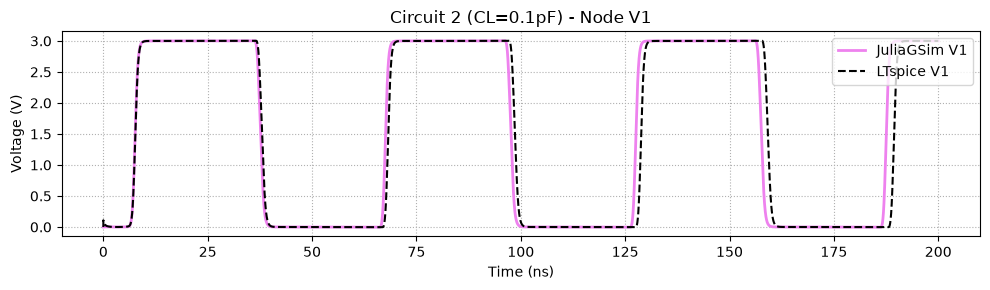

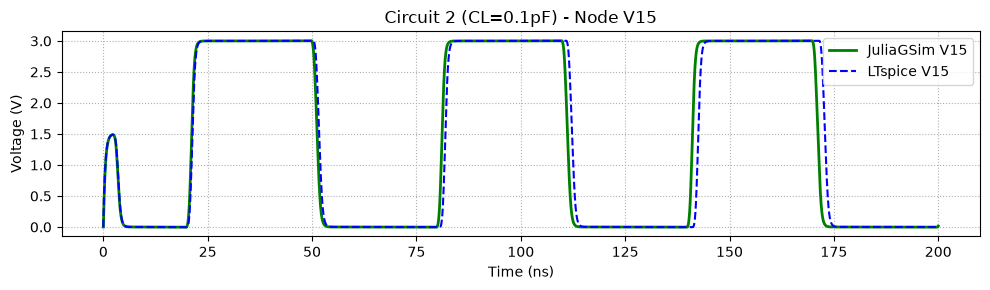

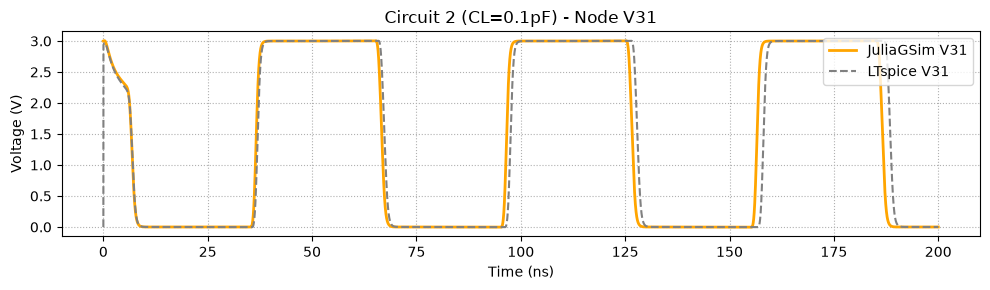

------------------------------------------------------------
 Worst Case #3 | Circuit 3 | CL = 0.103 pF | Freq Err = 1.00 %
 JuliaGSim Freq: 16.47 MHz | LTspice Freq: 16.30 MHz


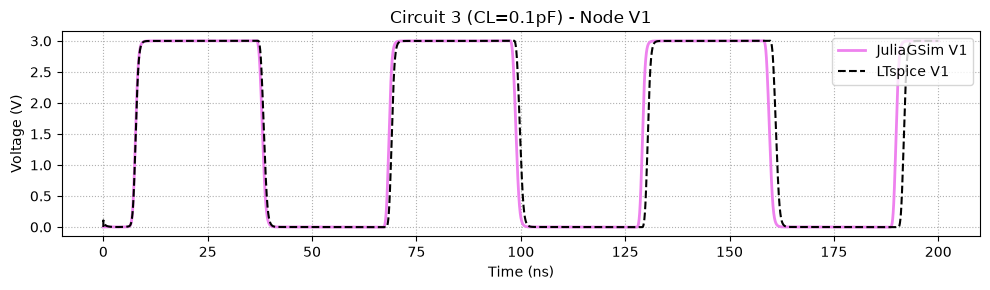

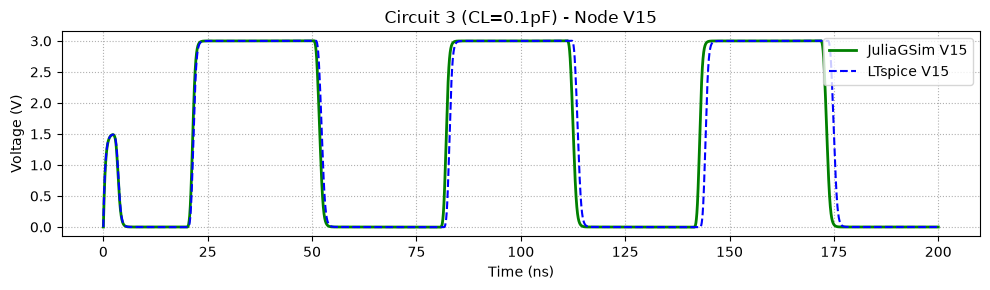

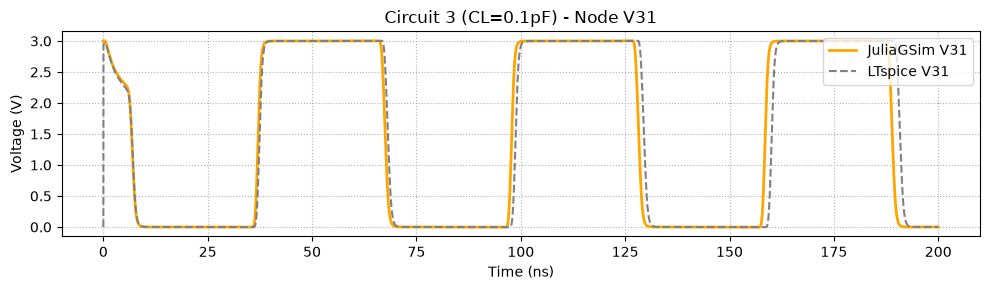

------------------------------------------------------------
 Worst Case #4 | Circuit 4 | CL = 0.104 pF | Freq Err = 0.99 %
 JuliaGSim Freq: 16.26 MHz | LTspice Freq: 16.11 MHz


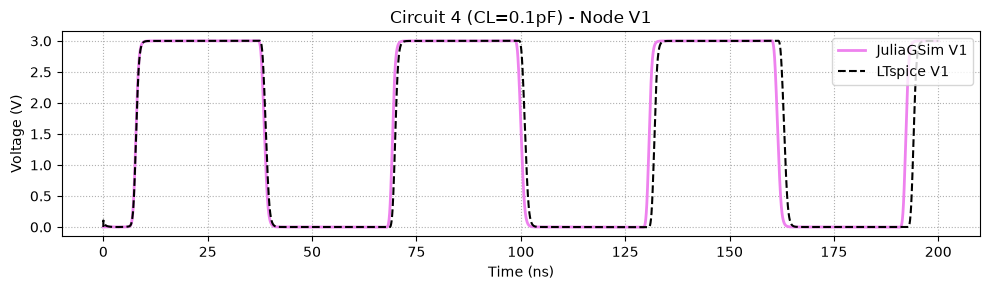

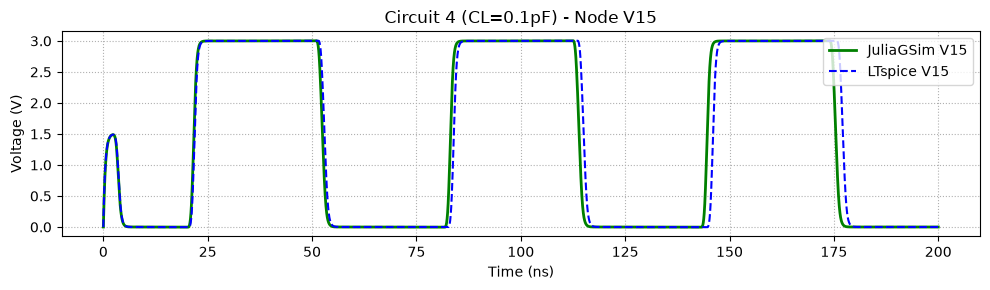

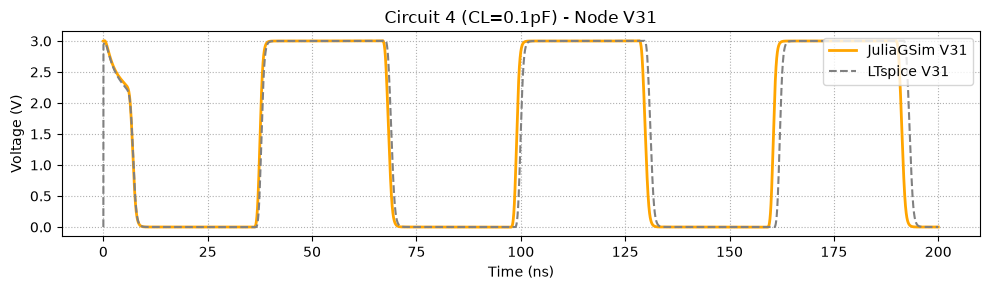

------------------------------------------------------------
 Worst Case #5 | Circuit 5 | CL = 0.105 pF | Freq Err = 0.98 %
 JuliaGSim Freq: 16.07 MHz | LTspice Freq: 15.91 MHz


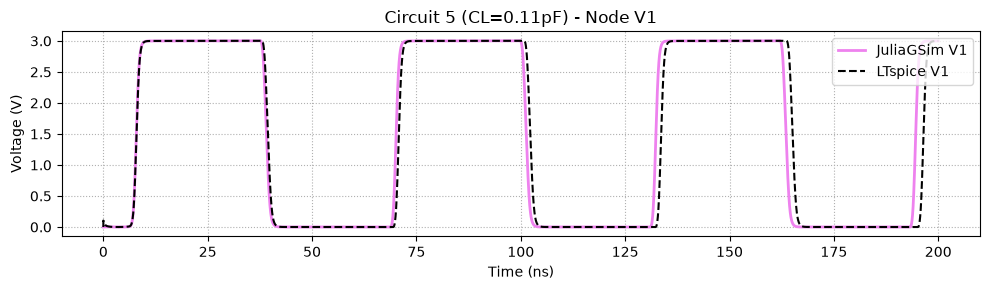

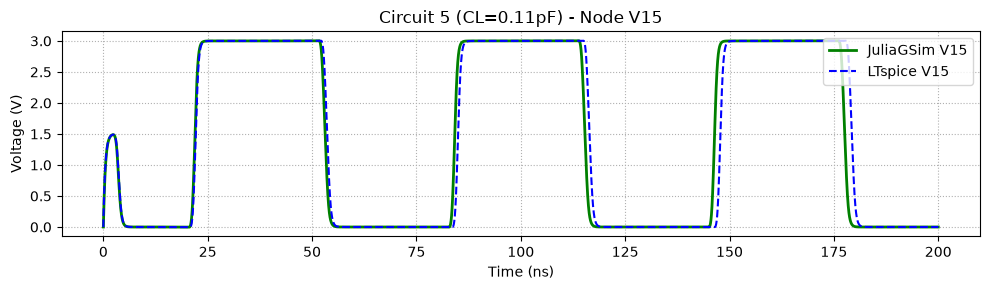

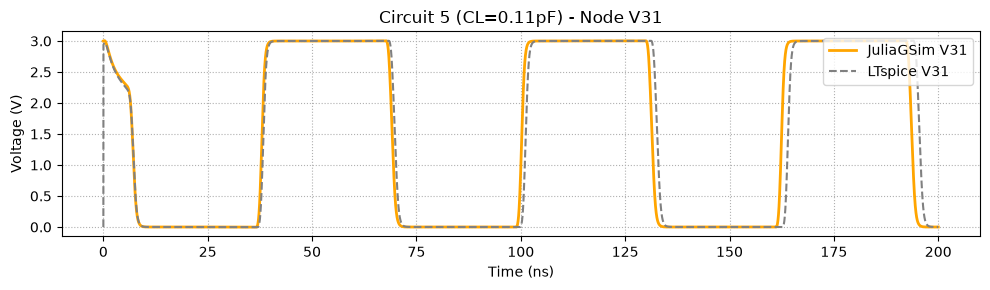

------------------------------------------------------------
 Worst Case #6 | Circuit 6 | CL = 0.107 pF | Freq Err = 0.96 %
 JuliaGSim Freq: 15.88 MHz | LTspice Freq: 15.73 MHz


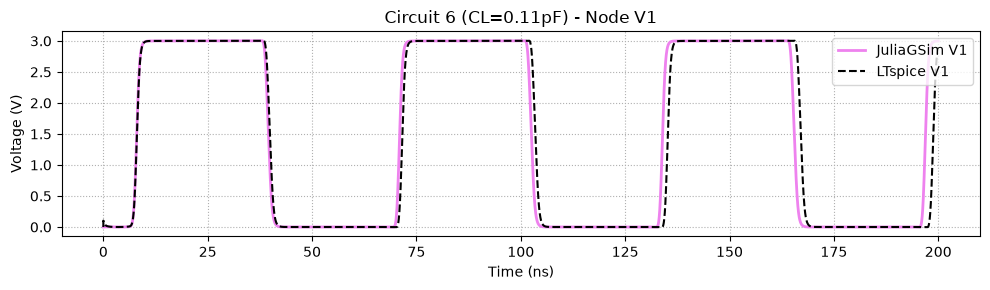

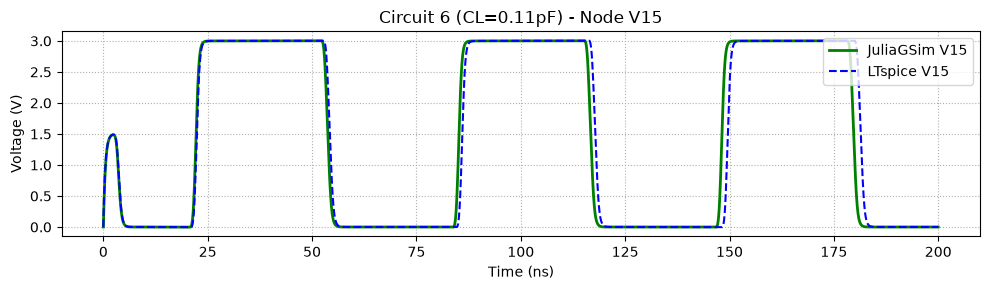

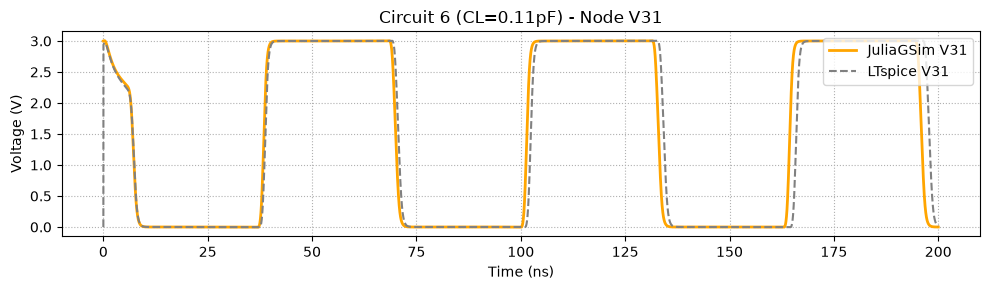

------------------------------------------------------------
 Worst Case #7 | Circuit 7 | CL = 0.108 pF | Freq Err = 0.95 %
 JuliaGSim Freq: 15.69 MHz | LTspice Freq: 15.54 MHz


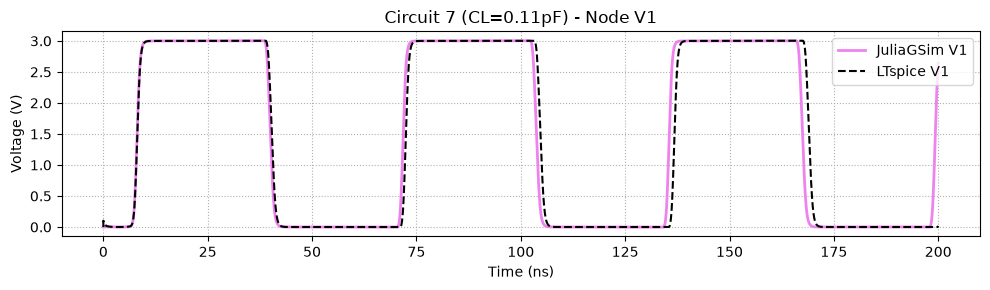

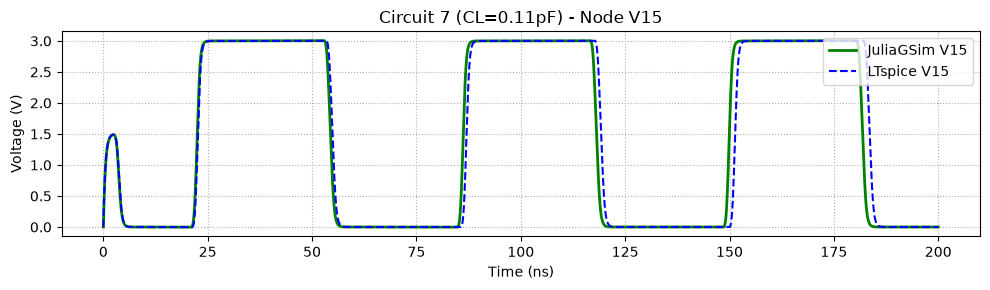

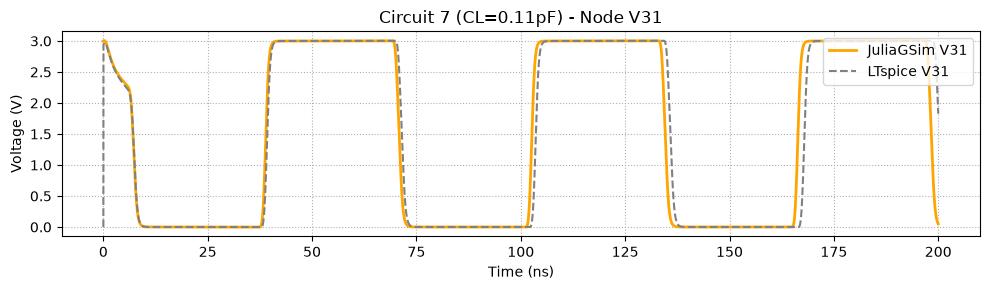

------------------------------------------------------------
 Worst Case #8 | Circuit 8 | CL = 0.109 pF | Freq Err = 0.94 %
 JuliaGSim Freq: 15.51 MHz | LTspice Freq: 15.36 MHz


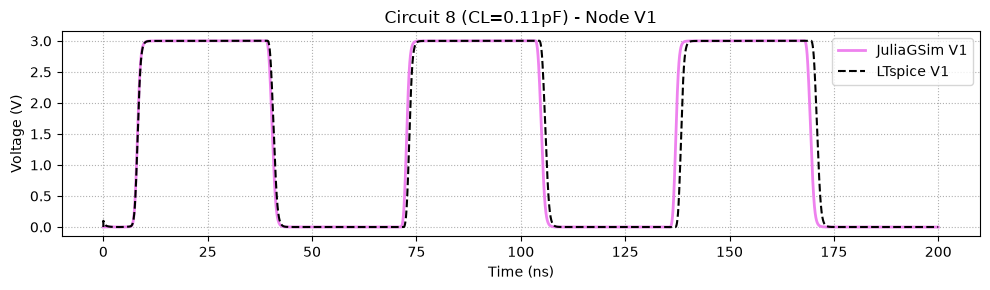

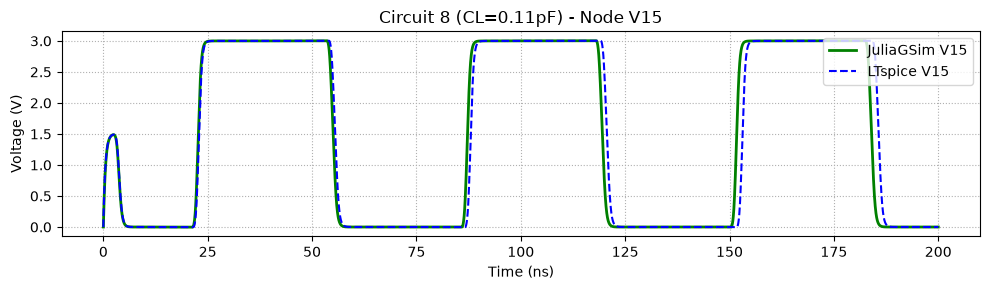

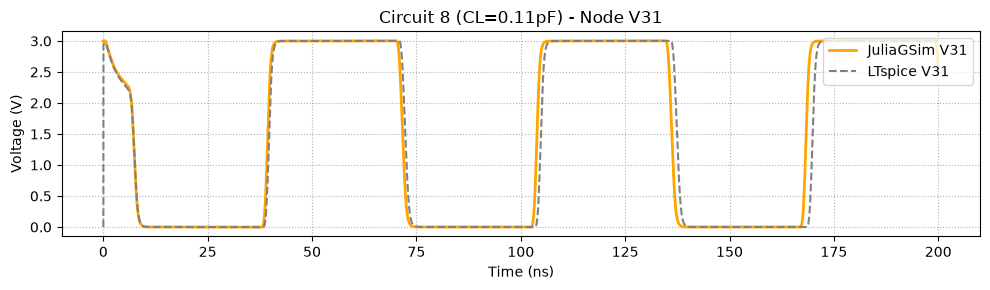

------------------------------------------------------------
 Worst Case #9 | Circuit 9 | CL = 0.111 pF | Freq Err = 0.93 %
 JuliaGSim Freq: 15.33 MHz | LTspice Freq: 15.19 MHz


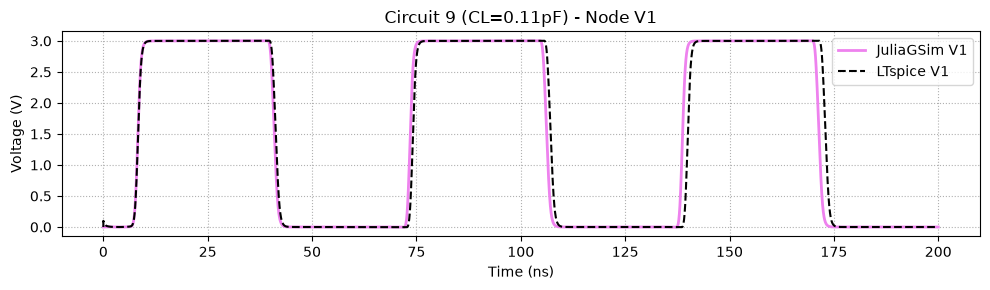

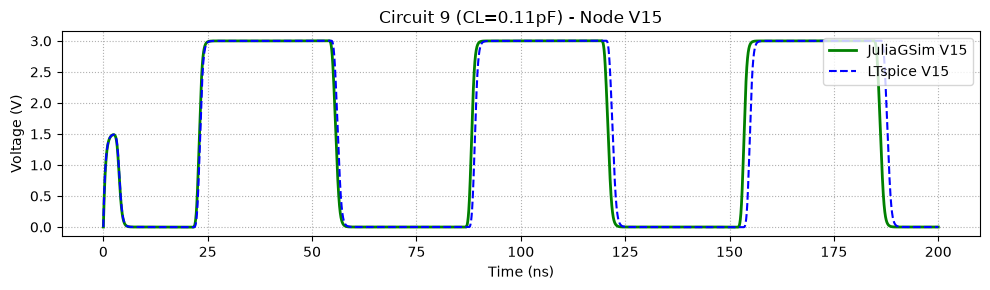

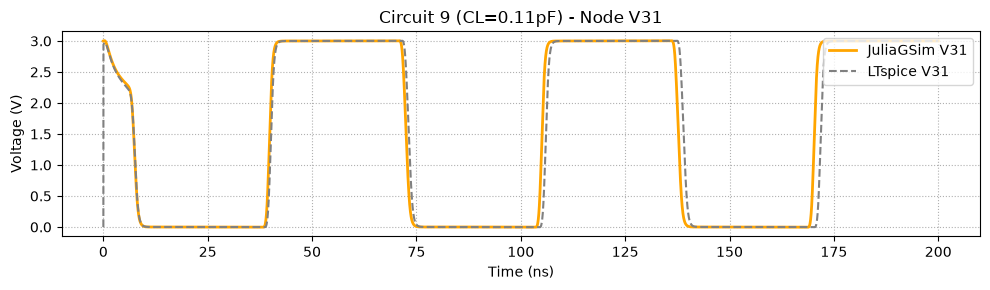

------------------------------------------------------------
 Worst Case #10 | Circuit 10 | CL = 0.112 pF | Freq Err = 0.92 %
 JuliaGSim Freq: 15.15 MHz | LTspice Freq: 15.02 MHz


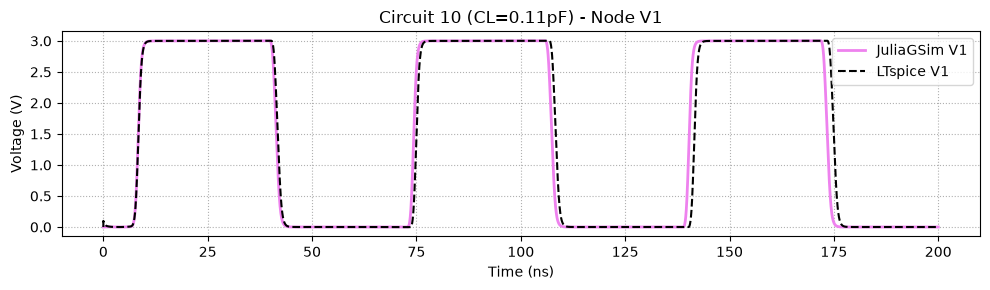

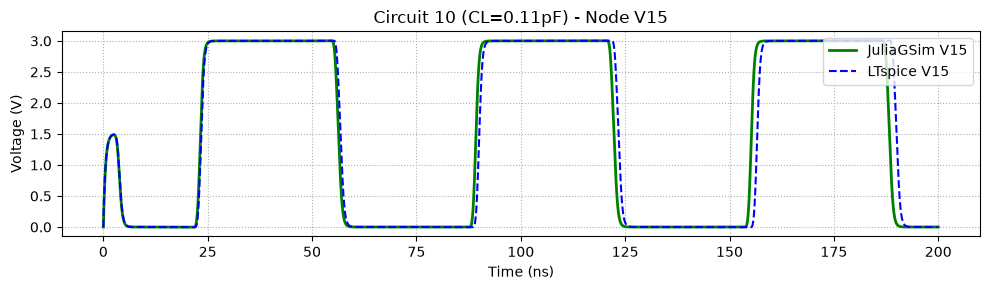

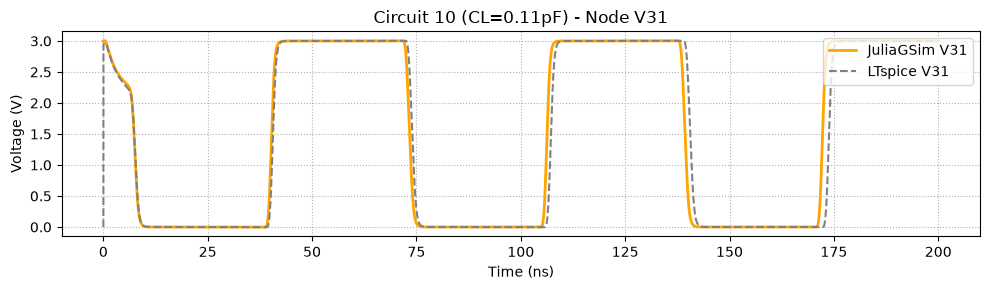

------------------------------------------------------------
 Worst Case #11 | Circuit 11 | CL = 0.113 pF | Freq Err = 0.91 %
 JuliaGSim Freq: 14.98 MHz | LTspice Freq: 14.85 MHz


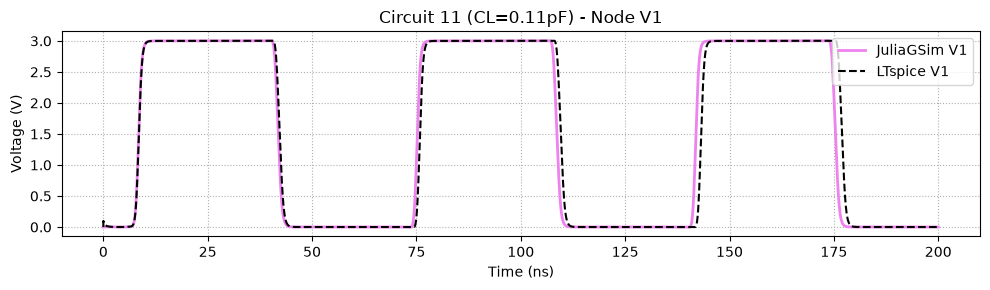

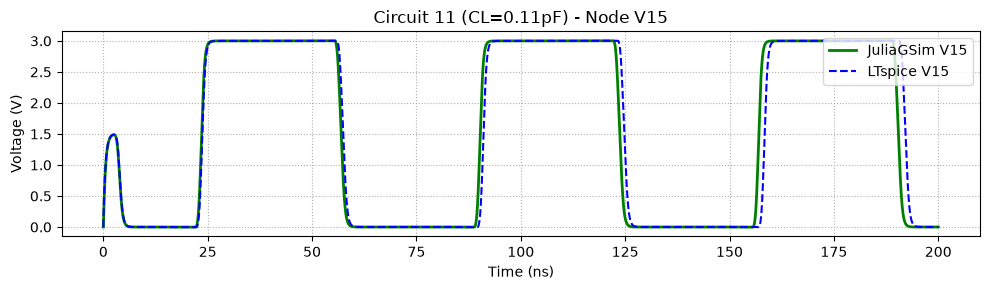

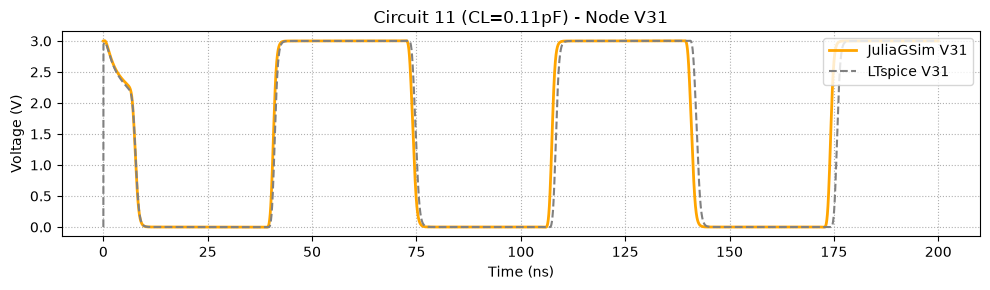

------------------------------------------------------------
 Worst Case #12 | Circuit 12 | CL = 0.115 pF | Freq Err = 0.90 %
 JuliaGSim Freq: 14.82 MHz | LTspice Freq: 14.68 MHz


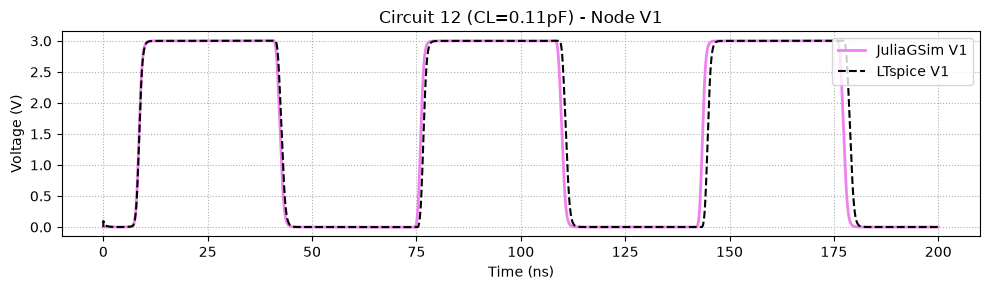

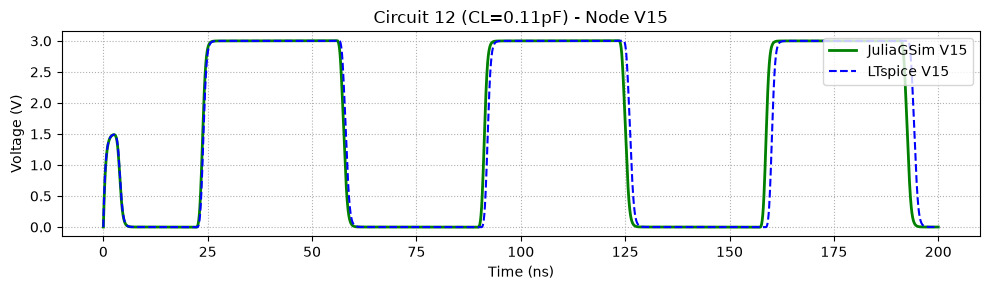

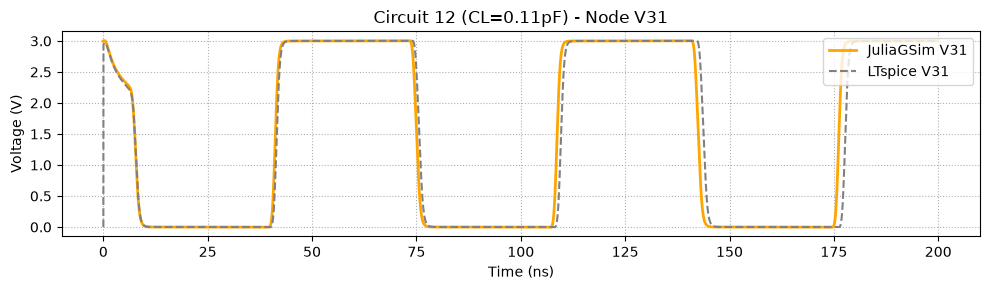

------------------------------------------------------------
 Worst Case #13 | Circuit 13 | CL = 0.116 pF | Freq Err = 0.89 %
 JuliaGSim Freq: 14.65 MHz | LTspice Freq: 14.52 MHz


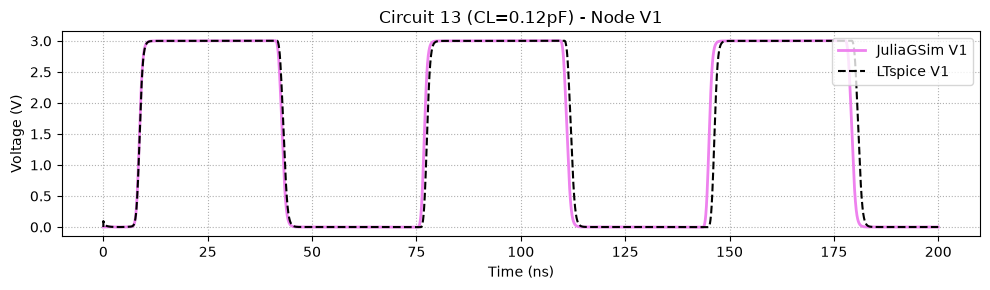

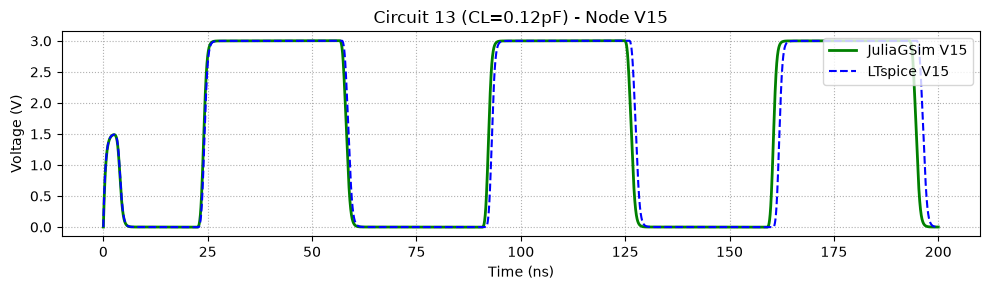

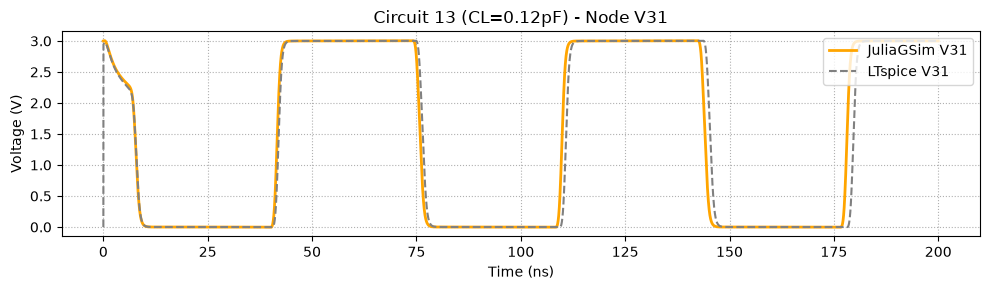

------------------------------------------------------------
 Worst Case #14 | Circuit 14 | CL = 0.117 pF | Freq Err = 0.88 %
 JuliaGSim Freq: 14.49 MHz | LTspice Freq: 14.37 MHz


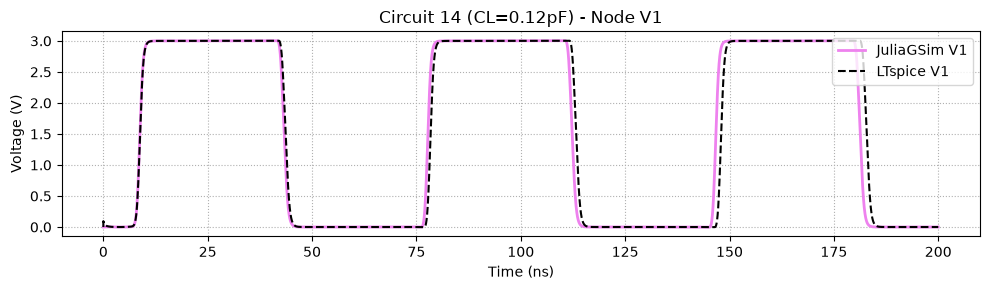

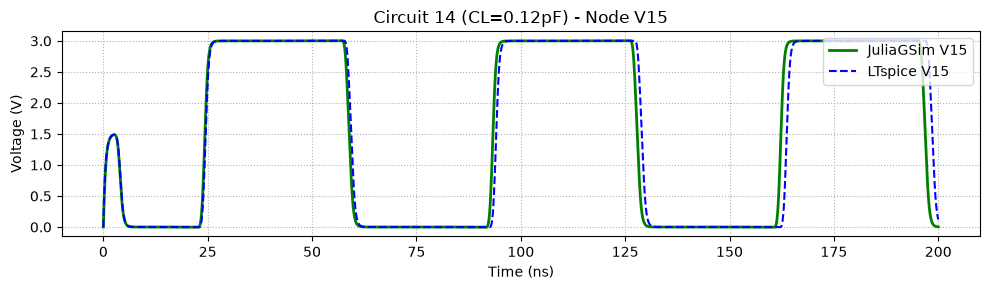

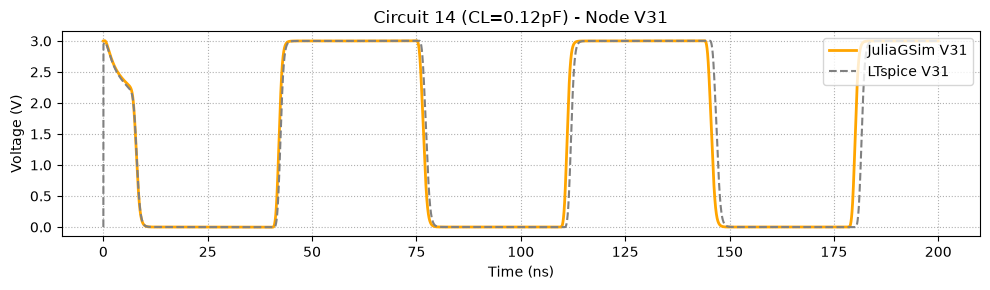

------------------------------------------------------------
 Worst Case #15 | Circuit 15 | CL = 0.119 pF | Freq Err = 0.87 %
 JuliaGSim Freq: 14.34 MHz | LTspice Freq: 14.21 MHz


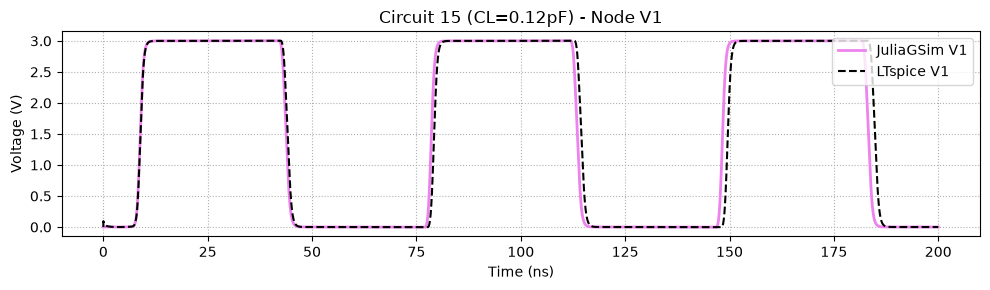

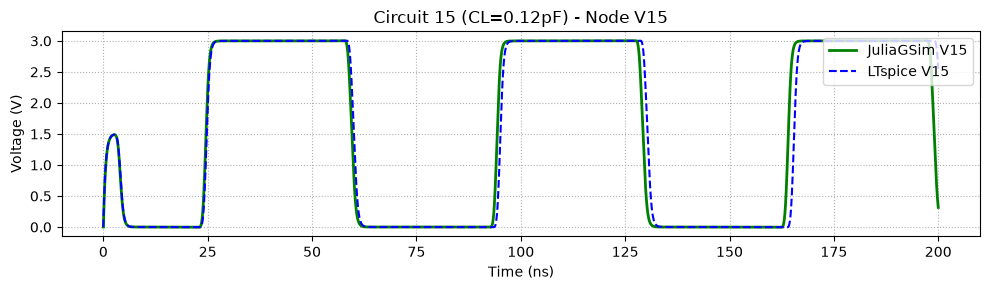

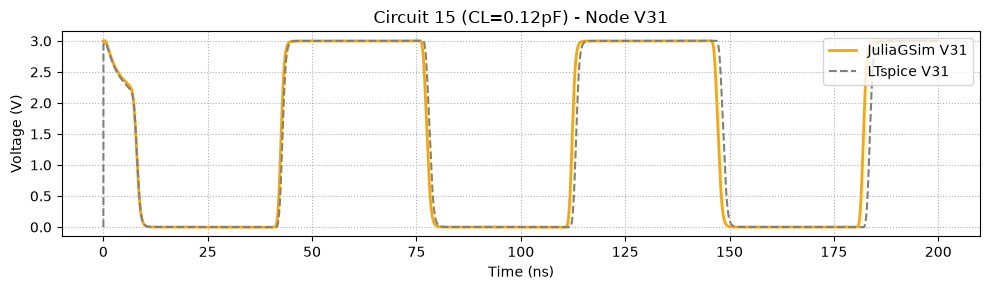

------------------------------------------------------------
 Worst Case #16 | Circuit 16 | CL = 0.120 pF | Freq Err = 0.86 %
 JuliaGSim Freq: 14.18 MHz | LTspice Freq: 14.06 MHz


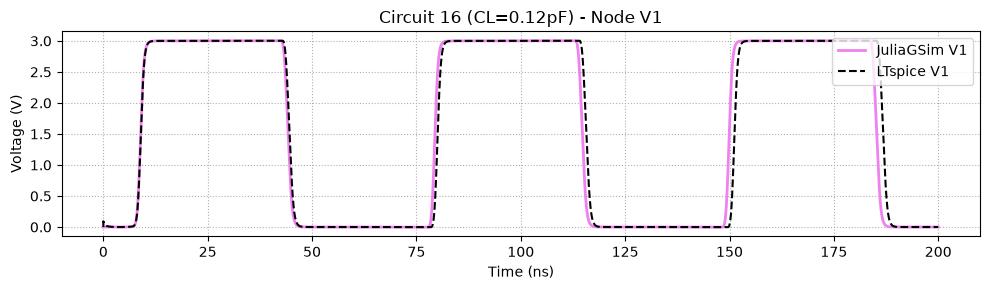

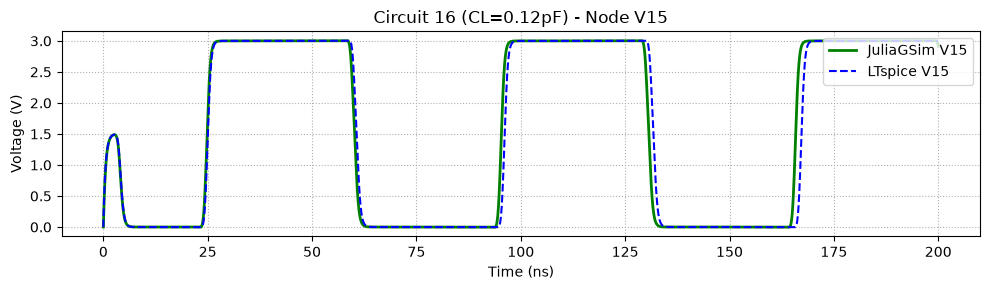

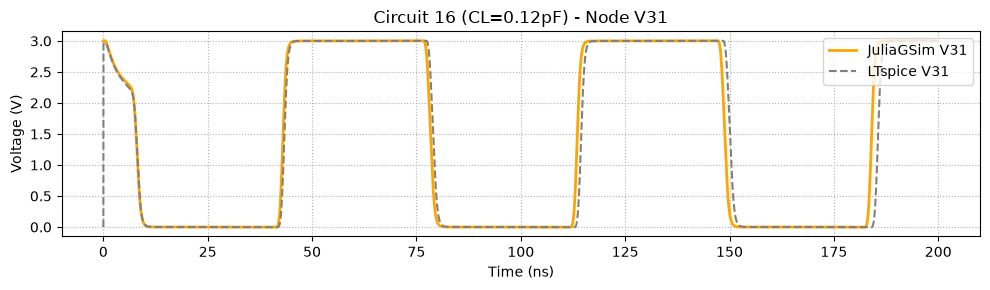

------------------------------------------------------------
 Worst Case #17 | Circuit 17 | CL = 0.121 pF | Freq Err = 0.85 %
 JuliaGSim Freq: 14.04 MHz | LTspice Freq: 13.92 MHz


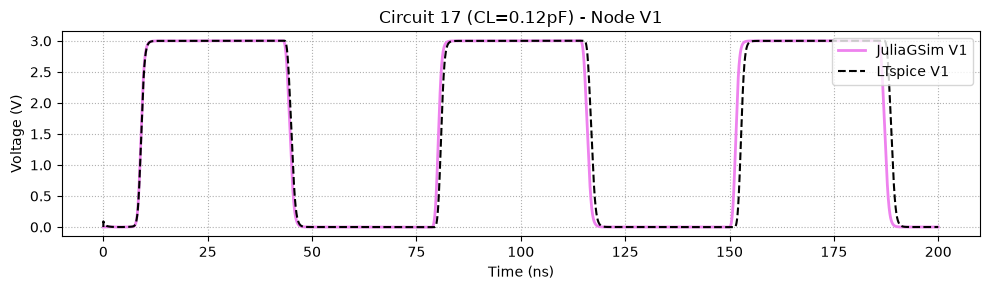

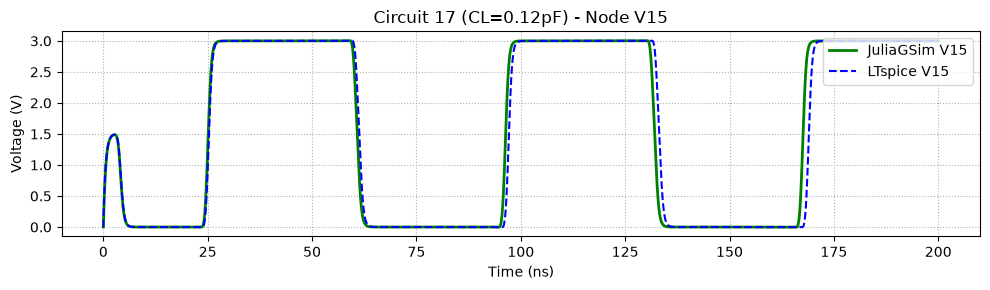

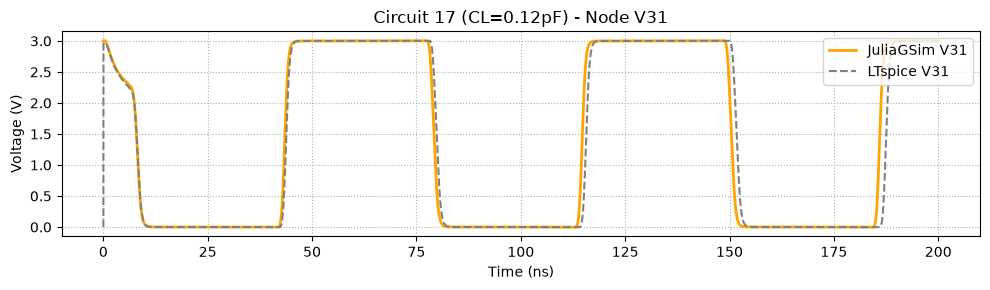

------------------------------------------------------------
 Worst Case #18 | Circuit 18 | CL = 0.123 pF | Freq Err = 0.84 %
 JuliaGSim Freq: 13.89 MHz | LTspice Freq: 13.77 MHz


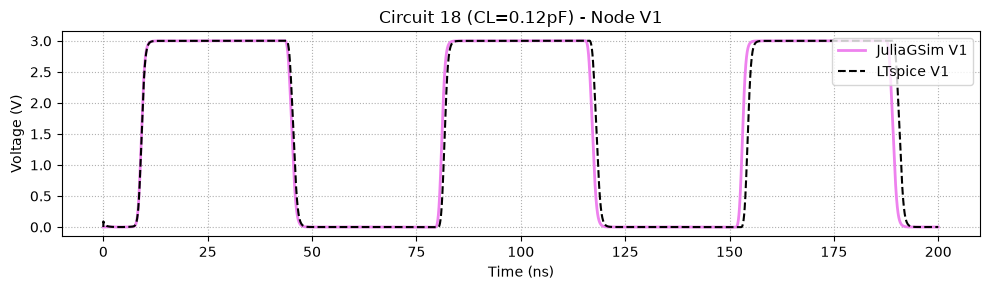

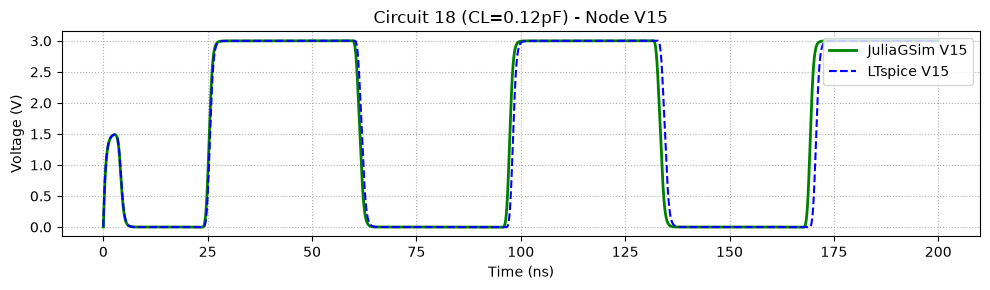

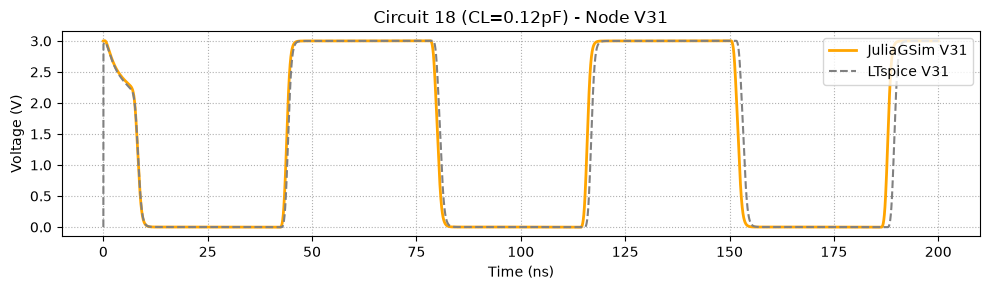

------------------------------------------------------------
 Worst Case #19 | Circuit 19 | CL = 0.124 pF | Freq Err = 0.83 %
 JuliaGSim Freq: 13.75 MHz | LTspice Freq: 13.63 MHz


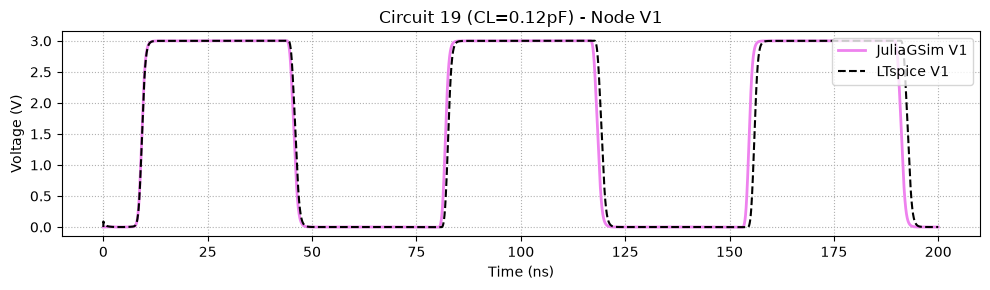

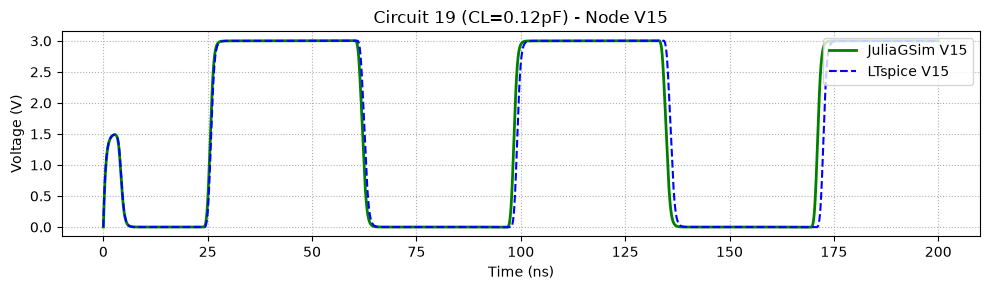

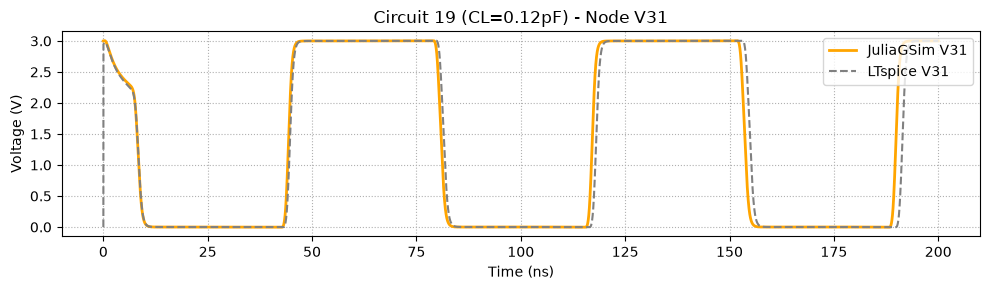

------------------------------------------------------------
 Worst Case #20 | Circuit 20 | CL = 0.125 pF | Freq Err = 0.82 %
 JuliaGSim Freq: 13.60 MHz | LTspice Freq: 13.49 MHz


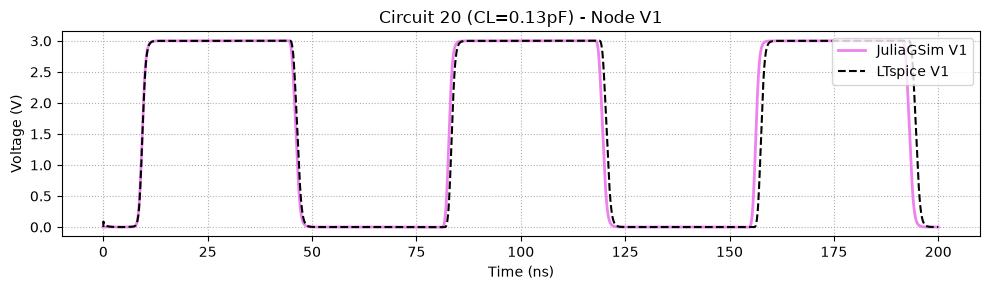

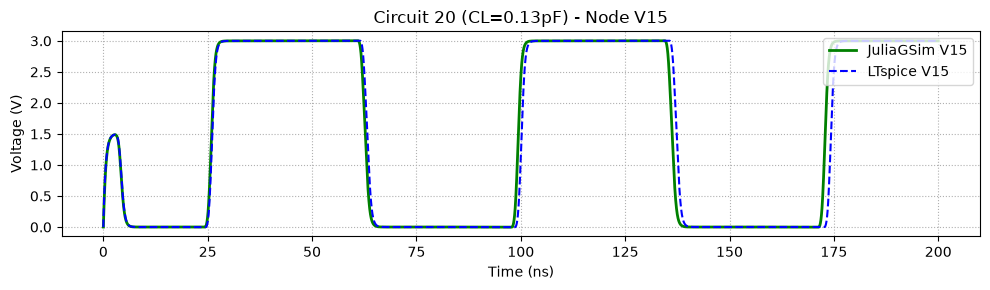

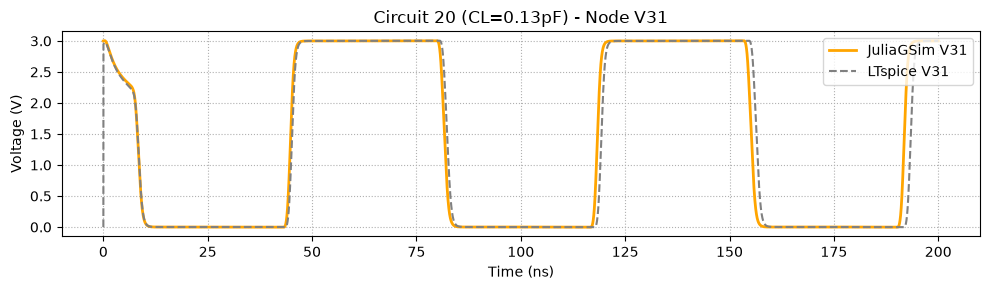

------------------------------------------------------------


In [1]:
# 0. Set Python Environment
ENV["JULIA_PYTHONCALL_EXE"] = "C:\\Users\\mohamed\\.conda\\envs\\Thesis_Optimizer_Sandbox_Copy\\python.exe"

using Printf
using StaticArrays
using PythonCall
using Random
using JLD2
using Interpolations
using Statistics
using Base.Threads

# ==============================================================================
# 1. Call the Surrogate definitions and the simulator Engine
# ==============================================================================
# 1. Load technology model definitions
include("C:\\Users\\mohamed\\Desktop\\ML\\CAD_projects\\Netlists\\GF_180nm_tech_work\\project\\New_Sim_tests\\Allah_help_me2\\Allah_Save_me\\New folder\\system\\Julia_GSim\\Vector_Sim_Engine\\Surrogate_definitions.jl")

# 2. Load the Engine (choose Static for small circuits or Sparse for large circuits)
include("C:\\Users\\mohamed\\Desktop\\ML\\CAD_projects\\Netlists\\GF_180nm_tech_work\\project\\New_Sim_tests\\Allah_help_me2\\Allah_Save_me\\New folder\\system\\Julia_GSim\\Vector_Sim_Engine\\Static_Sim.jl")


# ==============================================================================
# 2. LTSPICE VERIFICATION GROUND TRUTH (31-STAGE)
# ==============================================================================
g = pydict()
pyexec(raw"""
import os, subprocess, numpy as np
from PyLTSpice import RawRead

def run_ltspice_ring31_tran(L_val, mn, mp, CL, BASE_DIR='.'):
    os.makedirs(BASE_DIR, exist_ok=True)
    LTSPICE_PATH = r"C:\Users\Mohamed\AppData\Local\Programs\ADI\LTspice\LTspice.exe"
    
    netlist = []
    netlist.append("* 31-Stage CMOS Ring Oscillator (VCO)")
    netlist.append(".inc cmos_tt.txt")
    netlist.append(".op")
    netlist.append(".tran 0 200n 0 10p uic")
    netlist.append(".options plotwinsize=0")
    netlist.append("V0 vdd 0 3")
    
    # Generate 31 cascaded stages dynamically
    for i in range(1, 32):
        in_node = f"V{31 if i==1 else i-1}"
        out_node = f"V{i}"
        netlist.append(f"* STAGE {i}")
        netlist.append(f"M{2*i-1} {out_node} {in_node} vdd vdd pmos_3p3 w=0.5u l={L_val} m={mp}")
        netlist.append(f"M{2*i} {out_node} {in_node} 0 0 nmos_3p3 w=0.5u l={L_val} m={mn}")
        
        # Inject the kickstart initial condition ONLY on the last node
        if i == 31:
            netlist.append(f"C{i} {out_node} 0 {CL} ic=3")
        else:
            netlist.append(f"C{i} {out_node} 0 {CL}")
            
    netlist.append(".model NMOS NMOS")
    netlist.append(".model PMOS PMOS")
    netlist.append(f".lib {os.path.join(os.environ.get('LOCALAPPDATA', ''), 'LTspice', 'lib', 'cmp', 'standard.mos')}")
    
    # Measure frequency off Node V1
    netlist.append(".meas tran t_v1_1 TRIG v(V1) VAL=1.5 RISE=1")
    netlist.append(".meas tran t_v1_2 TRIG v(V1) VAL=1.5 RISE=2")
    netlist.append(".meas tran f_osc param abs(1/(t_v1_2-t_v1_1))")
    netlist.append(".end")
    
    netlist_str = "\n".join(netlist)
    sp_path = os.path.join(BASE_DIR, "tran_test_ring31.sp")
    raw_path = os.path.join(BASE_DIR, "tran_test_ring31.raw")
    log_path = os.path.join(BASE_DIR, "tran_test_ring31.log")
    
    if os.path.exists(raw_path):
        os.remove(raw_path)
        
    with open(sp_path, 'w', encoding='utf-8') as f: 
        f.write(netlist_str)
        
    subprocess.run([LTSPICE_PATH, "-b", "-run", sp_path], cwd=BASE_DIR, capture_output=True)
    raw = RawRead(raw_path)
    t = raw.get_trace("time").get_wave(0)
    
    # Extract 3 nodes across the ring
    v1 = raw.get_trace("V(v1)").get_wave(0)
    v15 = raw.get_trace("V(v15)").get_wave(0)
    v31 = raw.get_trace("V(v31)").get_wave(0)
    
    f_osc = 0.0
    if os.path.exists(log_path):
        with open(log_path, 'r', encoding='utf-8') as f:
            for line in f:
                if line.strip().startswith('f_osc:'):
                    try: f_osc = float(line.split('=')[1].strip())
                    except: pass
    return t, v1, v15, v31, f_osc
""", g)
run_ltspice_ring31_tran = g["run_ltspice_ring31_tran"]

# ==============================================================================
# 3. CIRCUIT DEFINITIONS & 300-BATCH SETUP
# ==============================================================================
struct CircuitParams
    L_val::Float64
    mp::Float64
    mn::Float64
    CL::Float64
end

N = 300
CL_arr = range(0.1e-12, 0.5e-12, length=N)

circuits = Vector{CircuitParams}(undef, N)
for i in 1:N
    circuits[i] = CircuitParams(300e-9, 3.33, 1.0, CL_arr[i])
end

println("\n====================================================================")
println(" TRANSIENT BATCH EVALUATION: $(N) CIRCUITS (31-STAGE RING OSCILLATOR)")
println("====================================================================")

sim_tran = JuliaGSim(surrogate_model)
add_vsource!(sim_tran, "V0", "vdd", "0", 3.0)

# Build the 31 stages dynamically in Julia
for i in 1:31
    in_node = i == 1 ? "V31" : "V$(i-1)"
    out_node = "V$i"
    
    add_pmos!(sim_tran, "MP$i", d=out_node, g=in_node, s="vdd", b="vdd", M=:mp, L=:L_val)
    add_nmos!(sim_tran, "MN$i", d=out_node, g=in_node, s="0", b="0", M=:mn, L=:L_val)
    
    if i == 31
        add_cap!(sim_tran, "C$i", out_node, "0", :CL; ic=3.0)
    else
        add_cap!(sim_tran, "C$i", out_node, "0", :CL)
    end
end

compile!(sim_tran)

BASE_DIR = pwd()

# ==============================================================================
# 4. RUN JULIAGSIM (ALWAYS RUNS FRESH & OVERWRITES CACHE)
# ==============================================================================
println("\n>>> Running $(N)-Batch Transient Solves on $(nthreads()) Julia Threads (Gear Method)...")

t_stop = 200e-9
dt_init = 10e-12
dt_max = 10e-12 

results_x_hist = Vector{Matrix{Float64}}(undef, N)
results_t_hist = Vector{Vector{Float64}}(undef, N)

start_time = time()
@threads for i in 1:N
    t_hist, x_hist = solve_tran(sim_tran, circuits[i], t_stop, dt_init, uic=true, dt_max=dt_max, method=:gear)
    results_x_hist[i] = x_hist
    results_t_hist[i] = t_hist
end
total_time = time() - start_time

println("Julia $(N)-Circuit Transient Total Time: $(round(total_time, digits=4)) s")

# Save/overwrite fresh Julia simulation results to disk
julia_cache_file = joinpath(BASE_DIR, "julia_ring31_cache_$(N).jld2")
@save julia_cache_file results_t_hist results_x_hist total_time
println("    Saved fresh Julia results to: $julia_cache_file")

idx_v1 = findfirst(==("V1"), sim_tran.unknown_nodes)
idx_v15 = findfirst(==("V15"), sim_tran.unknown_nodes)
idx_v31 = findfirst(==("V31"), sim_tran.unknown_nodes)

# ==============================================================================
# 5. RUN LTSPICE BASELINE (ALWAYS RUNS FRESH & OVERWRITES CACHE)
# ==============================================================================
println("\n>>> Running LTspice baseline (Sequential)...")

spice_times = Vector{Any}(undef, N)
spice_v1s   = Vector{Any}(undef, N)
spice_v15s  = Vector{Any}(undef, N)
spice_v31s  = Vector{Any}(undef, N)
spice_freqs = zeros(N)

start_spice = time()
for i in 1:N
    t_lt, v1_lt, v15_lt, v31_lt, f_osc_lt = run_ltspice_ring31_tran(
        circuits[i].L_val, circuits[i].mn, circuits[i].mp, circuits[i].CL, BASE_DIR
    )
    spice_times[i] = pyconvert(Array, t_lt)
    spice_v1s[i]   = pyconvert(Array, v1_lt)
    spice_v15s[i]  = pyconvert(Array, v15_lt)
    spice_v31s[i]  = pyconvert(Array, v31_lt)
    spice_freqs[i] = pyconvert(Float64, f_osc_lt)
    if i % 50 == 0; println("    LTspice progress: $i/$N circuits done..."); end
end
spice_time = time() - start_spice

println("LTspice Total Time: $(round(spice_time, digits=4)) s")

# Save/overwrite fresh LTspice simulation results to disk
spice_cache_file = joinpath(BASE_DIR, "ltspice_ring31_cache_$(N).jld2")
@save spice_cache_file spice_times spice_v1s spice_v15s spice_v31s spice_freqs spice_time
println("    Saved fresh LTspice results to: $spice_cache_file")

speedup = spice_time / total_time
println("\n======================================================================")
println(" 🚀 TRANSIENT PERFORMANCE SUMMARY (31-STAGE)")
println("======================================================================")
@printf(" JuliaGSim Time : %.3f seconds\n", total_time)
@printf(" LTspice Time   : %.3f seconds\n", spice_time)
@printf(" Speedup Factor : %.2fx faster than LTspice!\n", speedup)
println("======================================================================\n")

# ==============================================================================
# 6. FREQUENCY EXTRACTION & FULL 300-CIRCUIT COMPARISON TABLE
# ==============================================================================
jl_freqs = zeros(N)
for i in 1:N
    times = results_t_hist[i]
    v1_arr = results_x_hist[i][idx_v1, :]
    
    t_v1_1, t_v1_2 = 0.0, 0.0
    rise_count = 0
    for j in 2:length(times)
        if v1_arr[j-1] < 1.5 && v1_arr[j] >= 1.5
            # Precise linear interpolation of 1.5V crossing to match SPICE
            t_cross = times[j-1] + (1.5 - v1_arr[j-1]) * (times[j] - times[j-1]) / (v1_arr[j] - v1_arr[j-1])
            rise_count += 1
            if rise_count == 1
                t_v1_1 = t_cross
            elseif rise_count == 2
                t_v1_2 = t_cross
                break
            end
        end
    end
    jl_freqs[i] = (rise_count >= 2) ? abs(1.0 / (t_v1_2 - t_v1_1)) : 0.0
end

println("==========================================================================================")
println(" DETAILED CIRCUIT RESULTS (FREQUENCY COMPARISON)")
println("==========================================================================================\n")
@printf("%-10s | %-12s | %-15s | %-15s | %-15s\n", "Circuit", "CL (pF)", "Julia Freq", "LTspice Freq", "Error (%)")
println(repeat("-", 75))

freq_errors = zeros(N)
for i in 1:N
    err = spice_freqs[i] > 0 ? abs(jl_freqs[i] - spice_freqs[i]) / spice_freqs[i] * 100 : 0.0
    freq_errors[i] = err
    @printf("%-10d | %-12.3f | %-11.2f MHz | %-11.2f MHz | %-11.2f %%\n", i, circuits[i].CL * 1e12, jl_freqs[i] / 1e6, spice_freqs[i] / 1e6, err)
end
println()

println("======================================================================")
println(" OVERALL ACCURACY STATISTICAL SUMMARY ($(N) CIRCUITS)")
println("======================================================================")
@printf(" Max Frequency Error     : %.2f %%\n", maximum(freq_errors))
@printf(" Mean Frequency Error    : %.2f %%\n", mean(freq_errors))
@printf(" Min Oscillation Freq    : %.2f MHz\n", minimum(jl_freqs)/1e6)
@printf(" Max Oscillation Freq    : %.2f MHz\n", maximum(jl_freqs)/1e6)
println("======================================================================\n")

# ==============================================================================
# 7. VCO TUNING CHARACTERISTIC: fosc vs. CL (RED for Julia, BLUE for LTspice)
# ==============================================================================
plt = pyimport("matplotlib.pyplot")

fig_tune = plt.figure(figsize=(10, 5))
CL_vals_pF = [circuits[i].CL * 1e12 for i in 1:N]

plt.plot(CL_vals_pF, jl_freqs ./ 1e6, color="red", linewidth=2.5, label="JuliaGSim")
plt.plot(CL_vals_pF, spice_freqs ./ 1e6, color="blue", linestyle="--", linewidth=2.0, label="LTspice")
plt.title("31-Stage Ring Oscillator Tuning: Frequency vs. Load Capacitance ($(N) Circuits)", fontsize=12)
plt.xlabel("Load Capacitance CL (pF)", fontsize=11)
plt.ylabel("Oscillation Frequency (MHz)", fontsize=11)
plt.legend(loc="upper right", fontsize=11)
plt.grid(true, which="both", ls=":")
plt.tight_layout()

buf_tune = pyimport("io").BytesIO()
fig_tune.savefig(buf_tune, format="png", bbox_inches="tight")
display(MIME("image/png"), pyconvert(Vector{UInt8}, buf_tune.getvalue()))
plt.close(fig_tune)
println()

# ==============================================================================
# 8. WAVEFORM PLOTS: TOP 20 CIRCUITS WITH HIGHEST MISMATCH (60 IMAGES TOTAL)
# ==============================================================================
worst_order = sortperm(freq_errors, rev=true)
worst_20 = worst_order[1:min(20, N)]

println("======================================================================")
println(" WAVEFORM PLOTS: TOP 20 CIRCUITS WITH HIGHEST FREQUENCY MISMATCH")
println(" (3 SEPARATE FIGURES PER CIRCUIT: V1, V15, V31 -> TOTAL 60 FIGURES)")
println("======================================================================\n")

for (rank, i) in enumerate(worst_20)
    times_jl_arr = results_t_hist[i]
    v1_arr = results_x_hist[i][idx_v1, :]
    v15_arr = results_x_hist[i][idx_v15, :]
    v31_arr = results_x_hist[i][idx_v31, :]

    println(repeat("=", 75))
    @printf(" Worst Case #%d | Circuit %d | CL = %.3f pF | Freq Err = %.2f %%\n", rank, i, circuits[i].CL * 1e12, freq_errors[i])
    @printf(" JuliaGSim Freq: %.2f MHz | LTspice Freq: %.2f MHz\n", jl_freqs[i]/1e6, spice_freqs[i]/1e6)
    println(repeat("=", 75))

    # PLOT 1: V1
    fig1 = plt.figure(figsize=(10, 3))
    plt.plot(times_jl_arr .* 1e9, v1_arr, color="violet", linewidth=2, label="JuliaGSim V1")
    plt.plot(spice_times[i] .* 1e9, spice_v1s[i], color="black", linestyle="--", label="LTspice V1")
    plt.title("Circuit $i (CL=$(round(circuits[i].CL*1e12, digits=2))pF) - Node V1")
    plt.xlabel("Time (ns)")
    plt.ylabel("Voltage (V)")
    plt.legend(loc="upper right")
    plt.grid(true, which="both", ls=":")
    plt.tight_layout()
    buf1 = pyimport("io").BytesIO()
    fig1.savefig(buf1, format="png", bbox_inches="tight")
    display(MIME("image/png"), pyconvert(Vector{UInt8}, buf1.getvalue()))
    plt.close(fig1)

    # PLOT 2: V15
    fig2 = plt.figure(figsize=(10, 3))
    plt.plot(times_jl_arr .* 1e9, v15_arr, color="green", linewidth=2, label="JuliaGSim V15")
    plt.plot(spice_times[i] .* 1e9, spice_v15s[i], color="blue", linestyle="--", label="LTspice V15")
    plt.title("Circuit $i (CL=$(round(circuits[i].CL*1e12, digits=2))pF) - Node V15")
    plt.xlabel("Time (ns)")
    plt.ylabel("Voltage (V)")
    plt.legend(loc="upper right")
    plt.grid(true, which="both", ls=":")
    plt.tight_layout()
    buf2 = pyimport("io").BytesIO()
    fig2.savefig(buf2, format="png", bbox_inches="tight")
    display(MIME("image/png"), pyconvert(Vector{UInt8}, buf2.getvalue()))
    plt.close(fig2)

    # PLOT 3: V31
    fig3 = plt.figure(figsize=(10, 3))
    plt.plot(times_jl_arr .* 1e9, v31_arr, color="orange", linewidth=2, label="JuliaGSim V31")
    plt.plot(spice_times[i] .* 1e9, spice_v31s[i], color="grey", linestyle="--", label="LTspice V31")
    plt.title("Circuit $i (CL=$(round(circuits[i].CL*1e12, digits=2))pF) - Node V31")
    plt.xlabel("Time (ns)")
    plt.ylabel("Voltage (V)")
    plt.legend(loc="upper right")
    plt.grid(true, which="both", ls=":")
    plt.tight_layout()
    buf3 = pyimport("io").BytesIO()
    fig3.savefig(buf3, format="png", bbox_inches="tight")
    display(MIME("image/png"), pyconvert(Vector{UInt8}, buf3.getvalue()))
    plt.close(fig3)

    println(repeat("-", 60))
end


## Sparse Sim 

Loading Native Julia AC-Capable Surrogates... (This only happens once)
Successfully loaded Native Julia LUTs!

 TRANSIENT BATCH EVALUATION: 300 CIRCUITS (31-STAGE RING OSCILLATOR)

>>> Compiling Generic/Sparse Arrays Engine for 31 nodes...
Compiled Generic Arrays Engine Successfully!

>>> Running 300-Batch Transient Solves on 20 Julia Threads (Gear Method)...
Julia 300-Circuit Transient Total Time: 24.442 s
    Saved fresh Julia results to: C:\Users\mohamed\Desktop\ML\CAD_projects\Netlists\GF_180nm_tech_work\project\New_Sim_tests\Allah_help_me2\Allah_Save_me\New folder\system\Testing\Spice_vs_Julia_Benchmarking\julia_ring31_cache_300.jld2

>>> Running LTspice baseline (Sequential)...
    LTspice progress: 50/300 circuits done...
    LTspice progress: 100/300 circuits done...
    LTspice progress: 150/300 circuits done...
    LTspice progress: 200/300 circuits done...
    LTspice progress: 250/300 circuits done...
    LTspice progress: 300/300 circuits done...
LTspice Total Time: 512.69

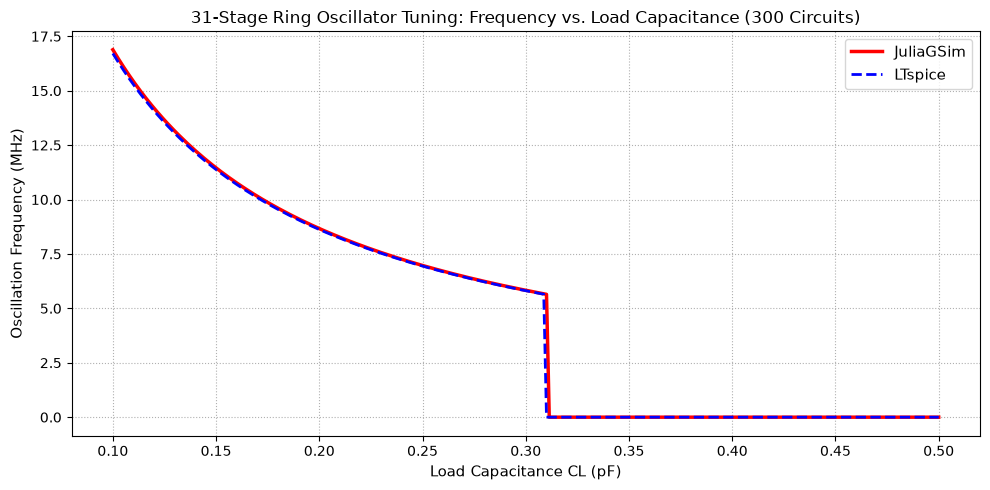


 WAVEFORM PLOTS: TOP 20 CIRCUITS WITH HIGHEST FREQUENCY MISMATCH
 (3 SEPARATE FIGURES PER CIRCUIT: V1, V15, V31 -> TOTAL 60 FIGURES)

 Worst Case #1 | Circuit 1 | CL = 0.100 pF | Freq Err = 1.03 %
 JuliaGSim Freq: 16.88 MHz | LTspice Freq: 16.71 MHz


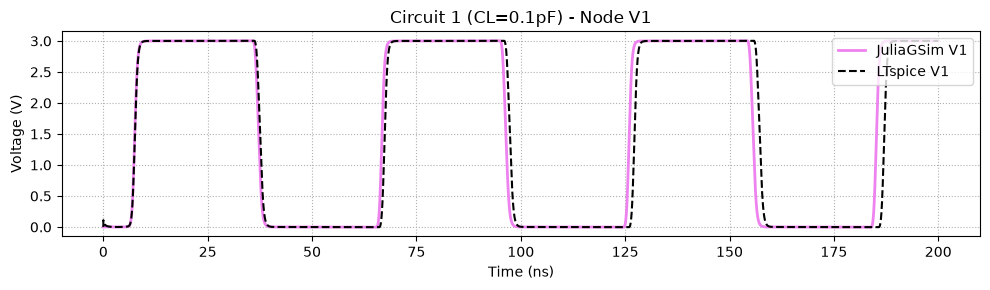

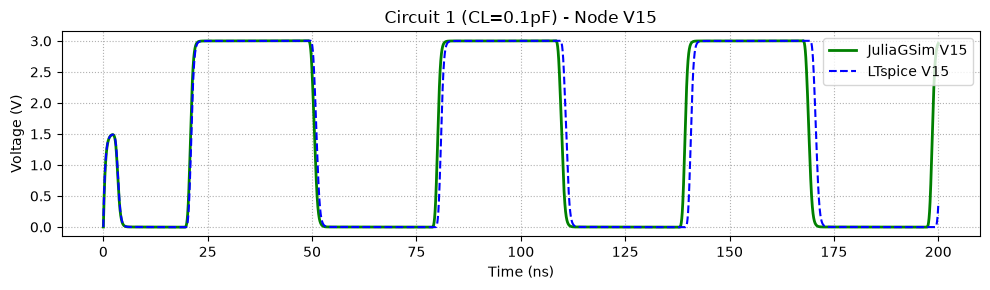

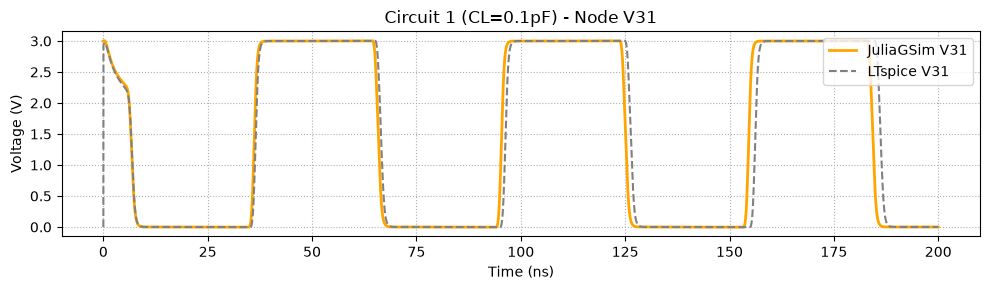

------------------------------------------------------------
 Worst Case #2 | Circuit 2 | CL = 0.101 pF | Freq Err = 1.01 %
 JuliaGSim Freq: 16.67 MHz | LTspice Freq: 16.51 MHz


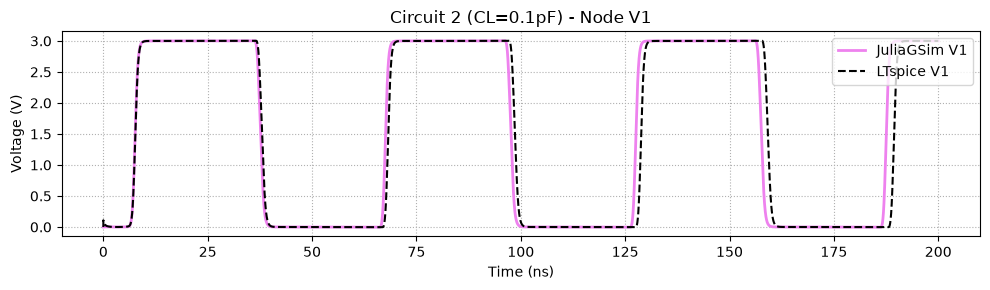

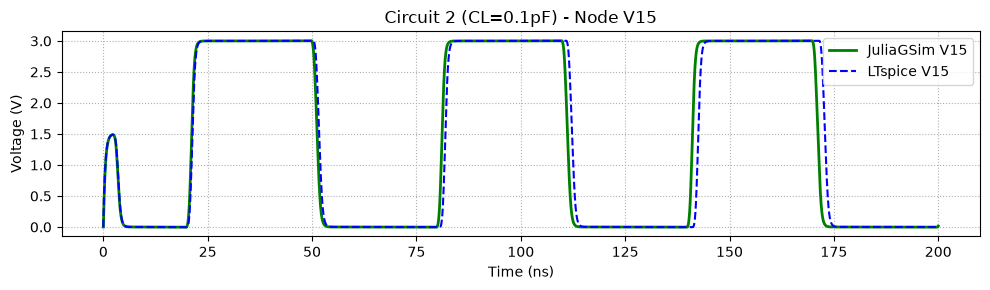

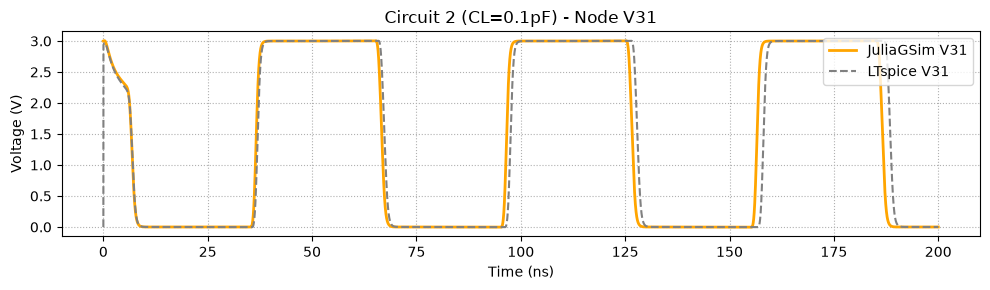

------------------------------------------------------------
 Worst Case #3 | Circuit 3 | CL = 0.103 pF | Freq Err = 1.00 %
 JuliaGSim Freq: 16.47 MHz | LTspice Freq: 16.30 MHz


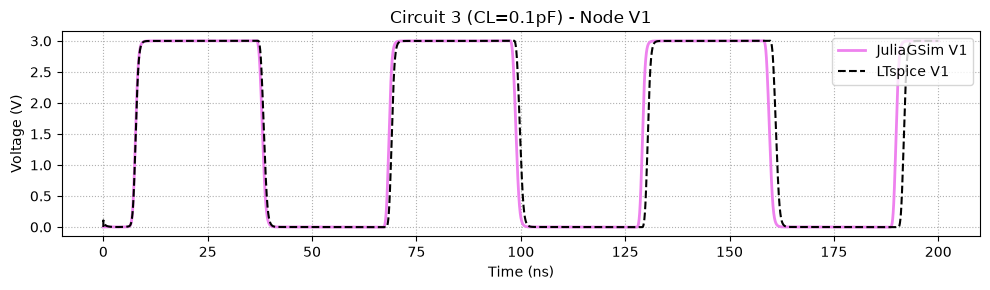

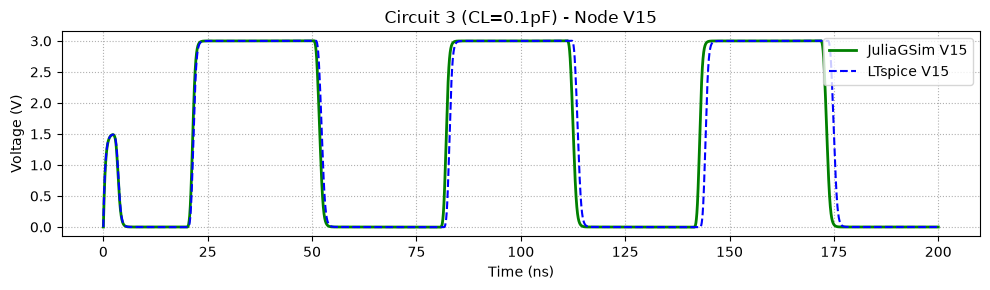

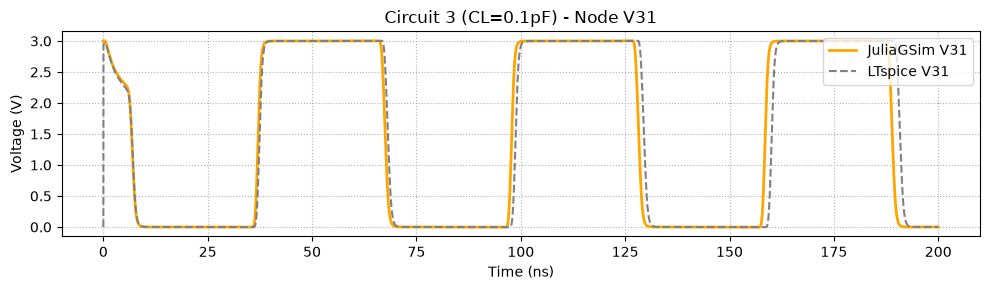

------------------------------------------------------------
 Worst Case #4 | Circuit 4 | CL = 0.104 pF | Freq Err = 0.99 %
 JuliaGSim Freq: 16.26 MHz | LTspice Freq: 16.11 MHz


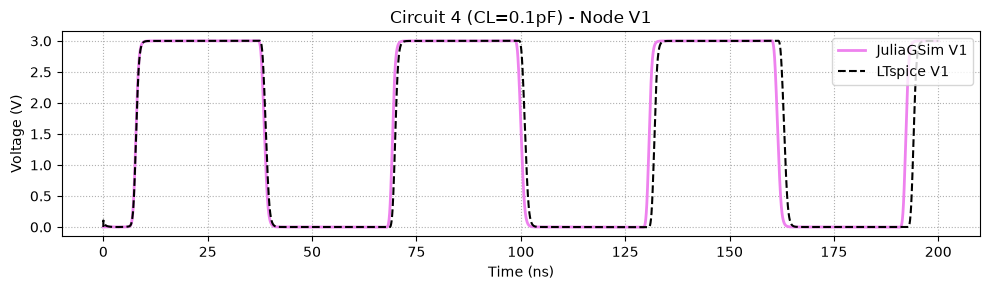

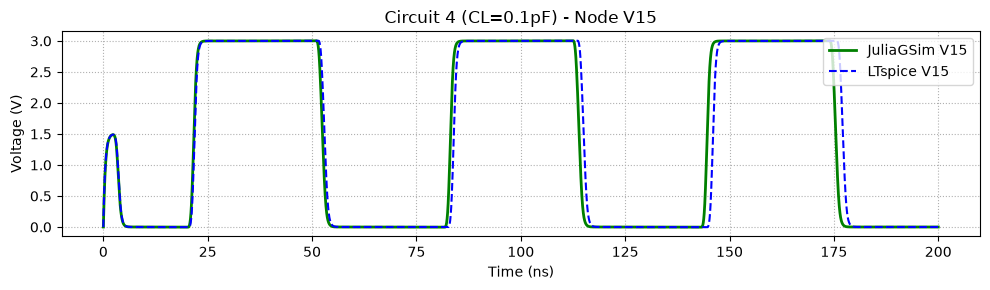

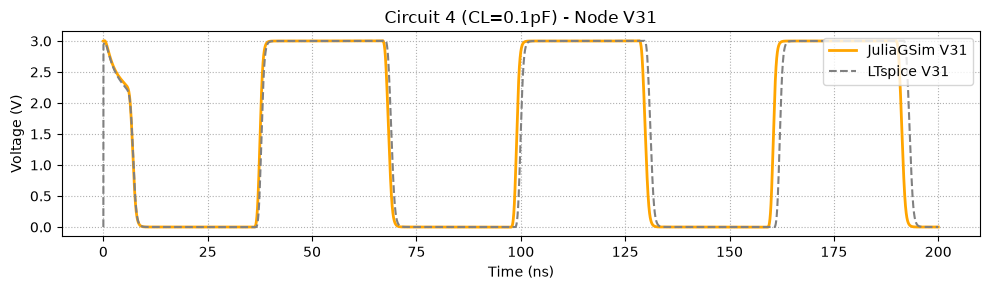

------------------------------------------------------------
 Worst Case #5 | Circuit 5 | CL = 0.105 pF | Freq Err = 0.98 %
 JuliaGSim Freq: 16.07 MHz | LTspice Freq: 15.91 MHz


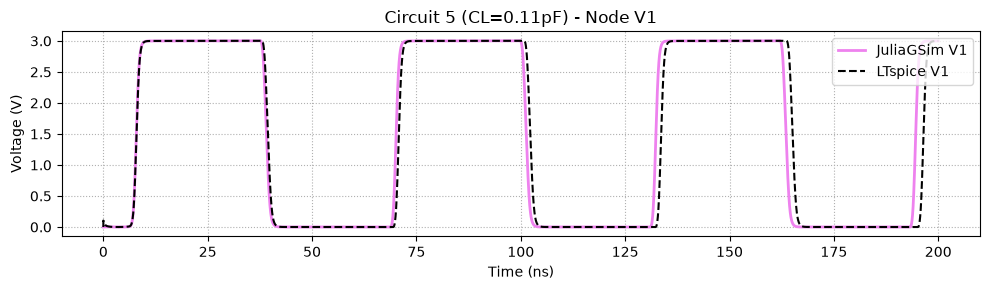

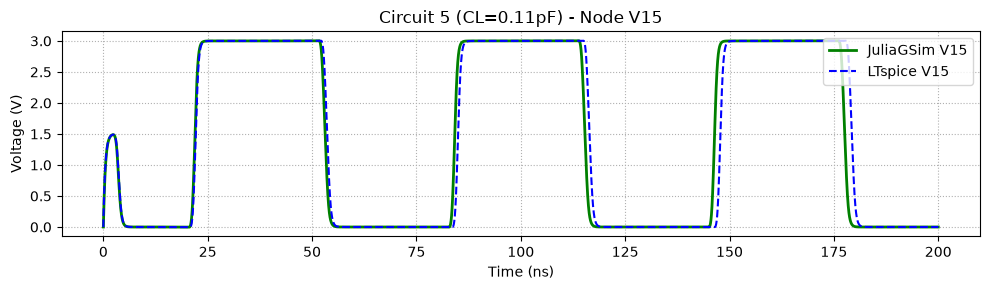

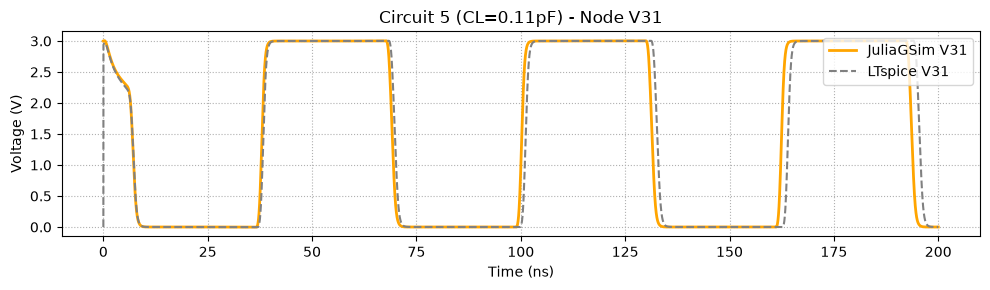

------------------------------------------------------------
 Worst Case #6 | Circuit 6 | CL = 0.107 pF | Freq Err = 0.96 %
 JuliaGSim Freq: 15.88 MHz | LTspice Freq: 15.73 MHz


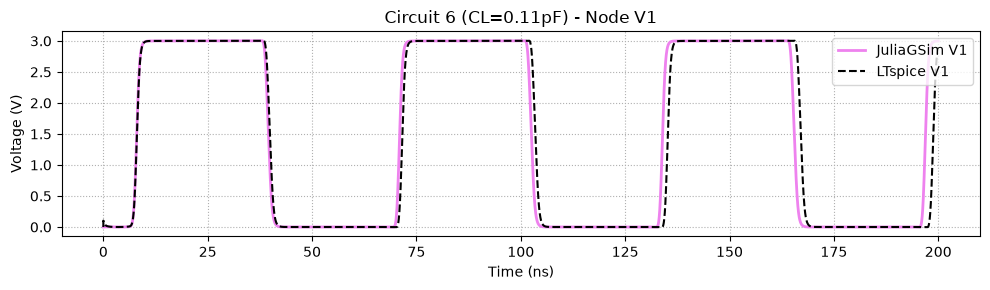

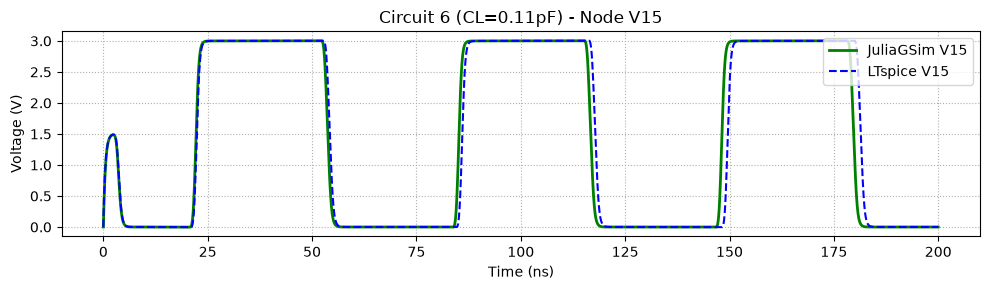

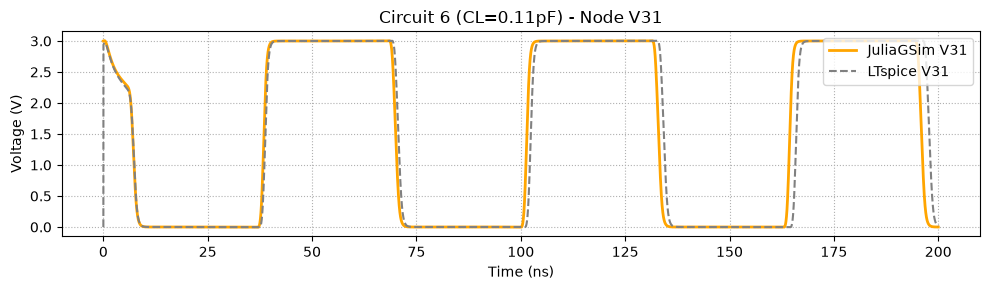

------------------------------------------------------------
 Worst Case #7 | Circuit 7 | CL = 0.108 pF | Freq Err = 0.95 %
 JuliaGSim Freq: 15.69 MHz | LTspice Freq: 15.54 MHz


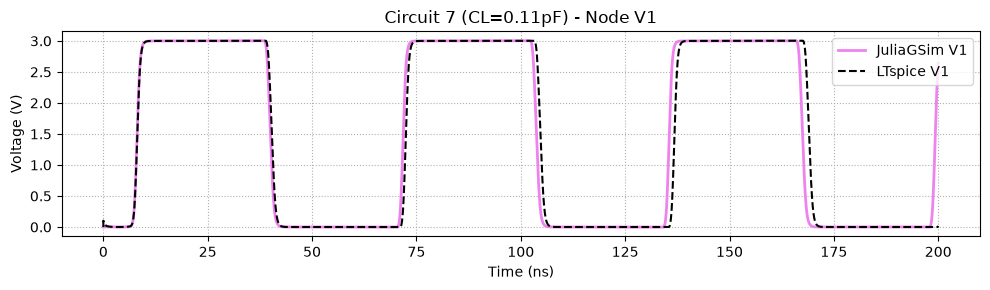

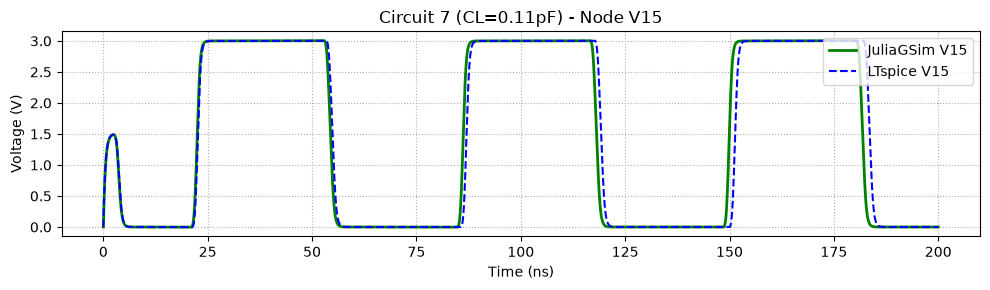

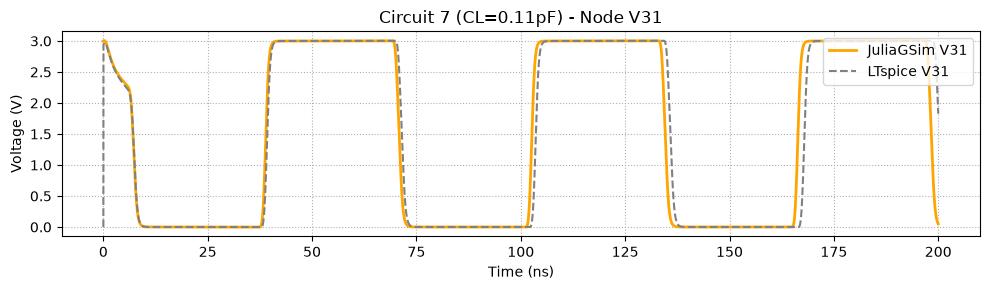

------------------------------------------------------------
 Worst Case #8 | Circuit 8 | CL = 0.109 pF | Freq Err = 0.94 %
 JuliaGSim Freq: 15.51 MHz | LTspice Freq: 15.36 MHz


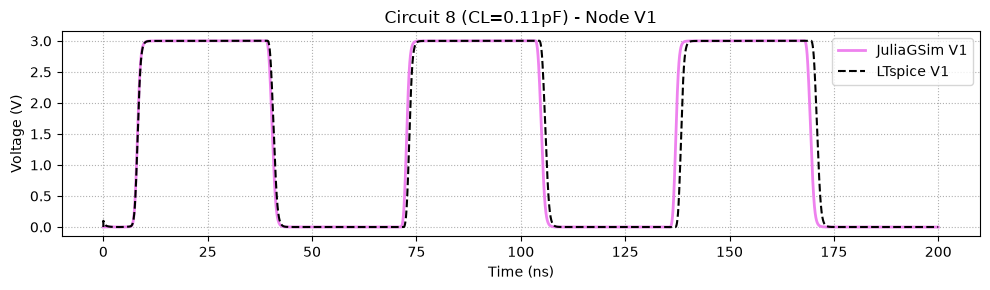

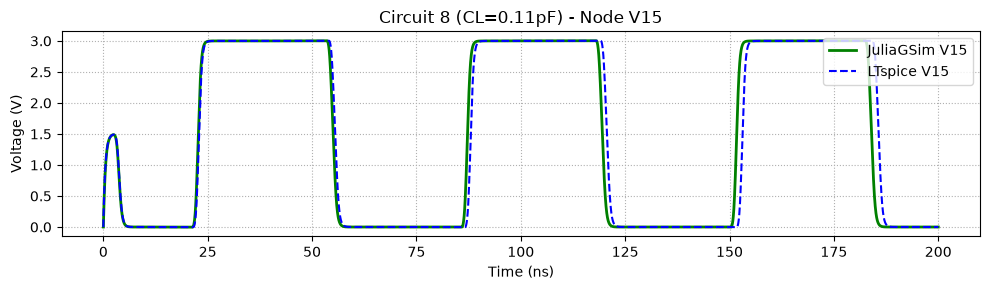

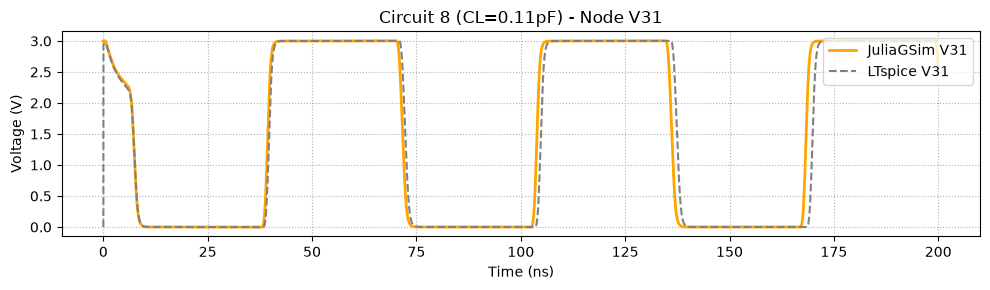

------------------------------------------------------------
 Worst Case #9 | Circuit 9 | CL = 0.111 pF | Freq Err = 0.93 %
 JuliaGSim Freq: 15.33 MHz | LTspice Freq: 15.19 MHz


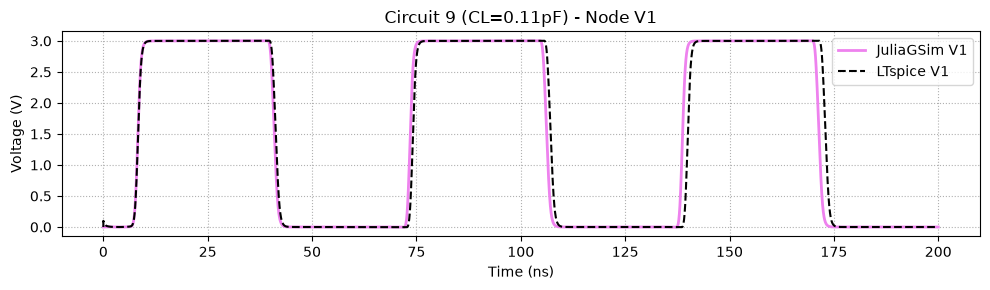

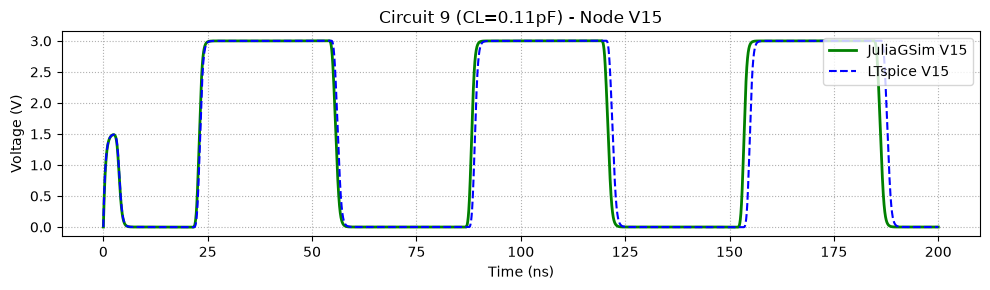

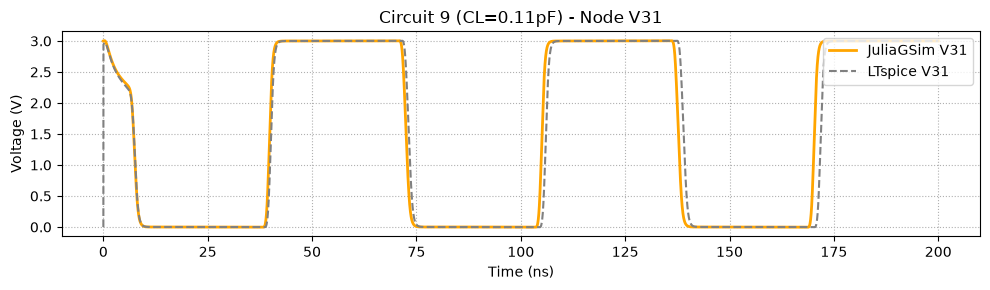

------------------------------------------------------------
 Worst Case #10 | Circuit 10 | CL = 0.112 pF | Freq Err = 0.92 %
 JuliaGSim Freq: 15.15 MHz | LTspice Freq: 15.02 MHz


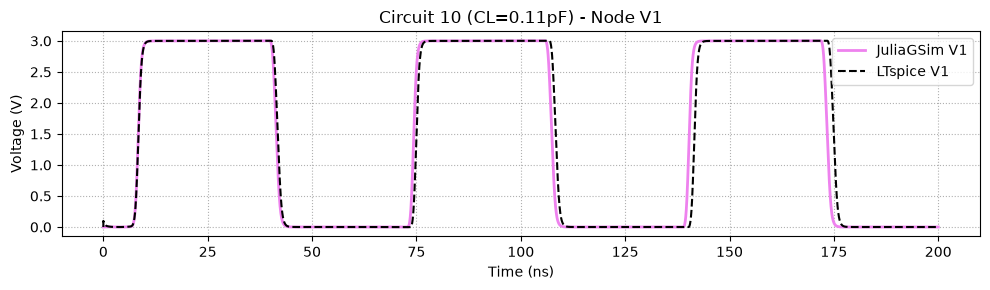

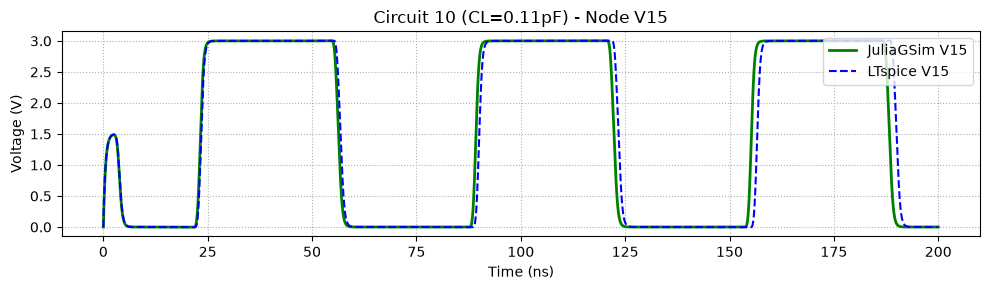

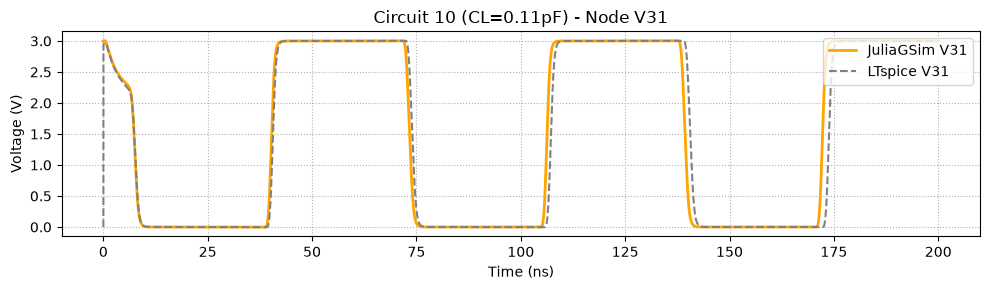

------------------------------------------------------------
 Worst Case #11 | Circuit 11 | CL = 0.113 pF | Freq Err = 0.91 %
 JuliaGSim Freq: 14.98 MHz | LTspice Freq: 14.85 MHz


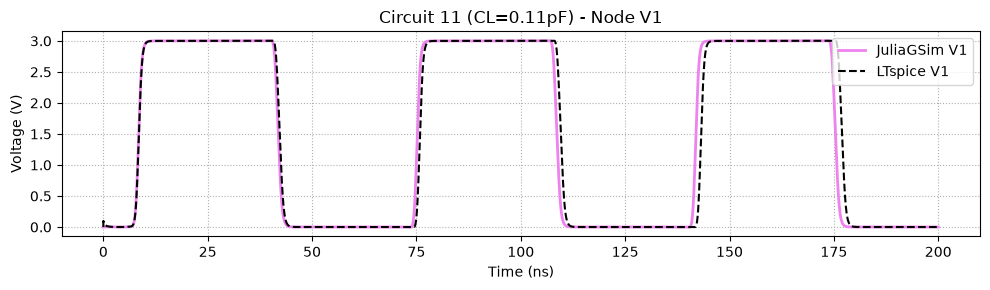

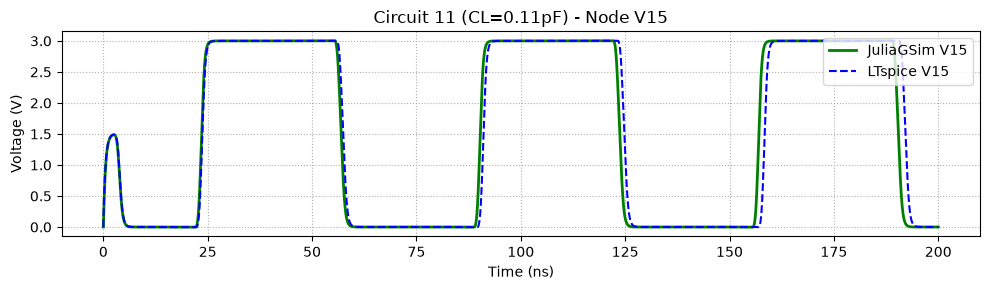

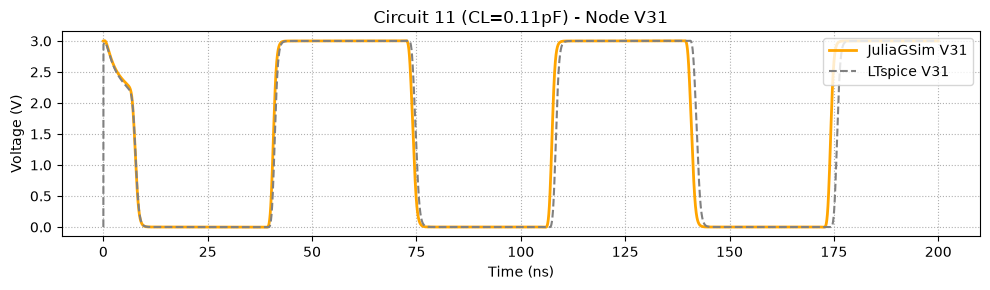

------------------------------------------------------------
 Worst Case #12 | Circuit 12 | CL = 0.115 pF | Freq Err = 0.90 %
 JuliaGSim Freq: 14.82 MHz | LTspice Freq: 14.68 MHz


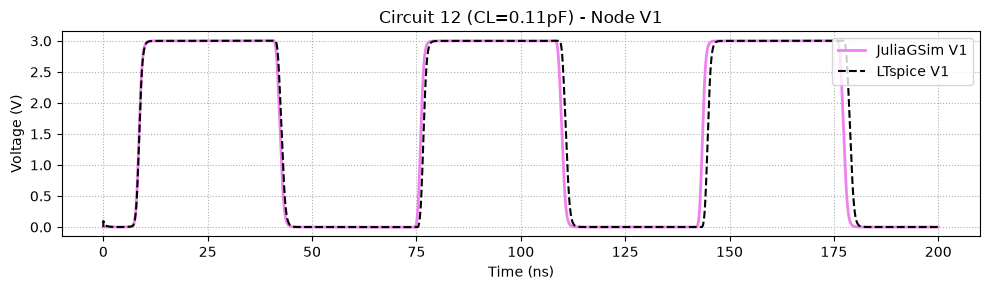

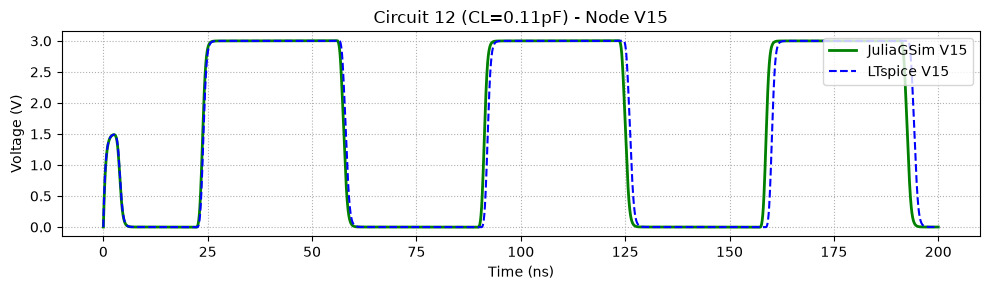

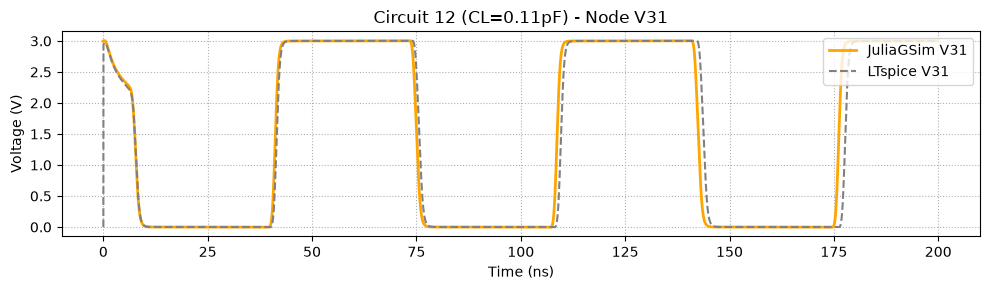

------------------------------------------------------------
 Worst Case #13 | Circuit 13 | CL = 0.116 pF | Freq Err = 0.89 %
 JuliaGSim Freq: 14.65 MHz | LTspice Freq: 14.52 MHz


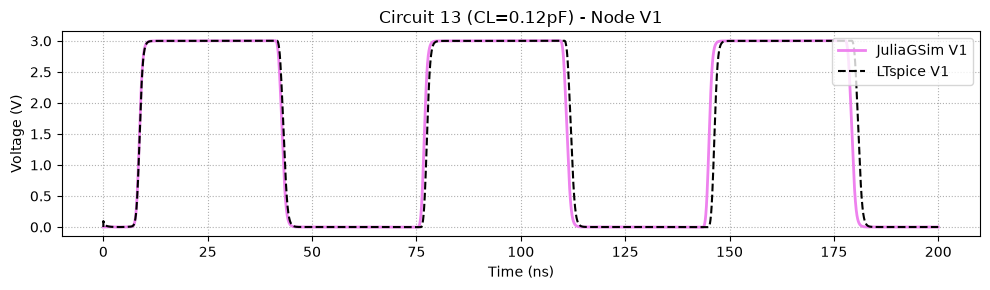

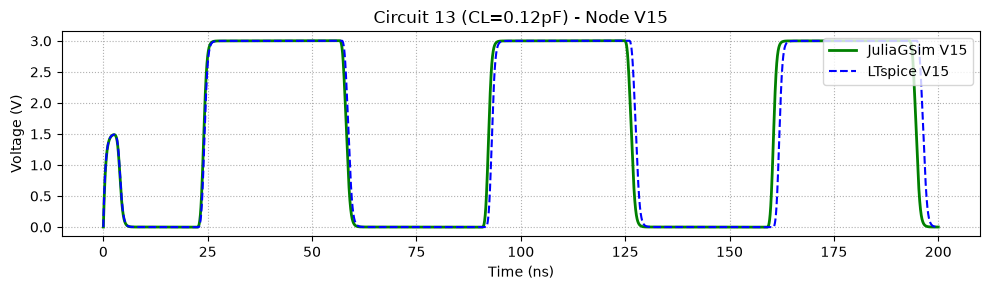

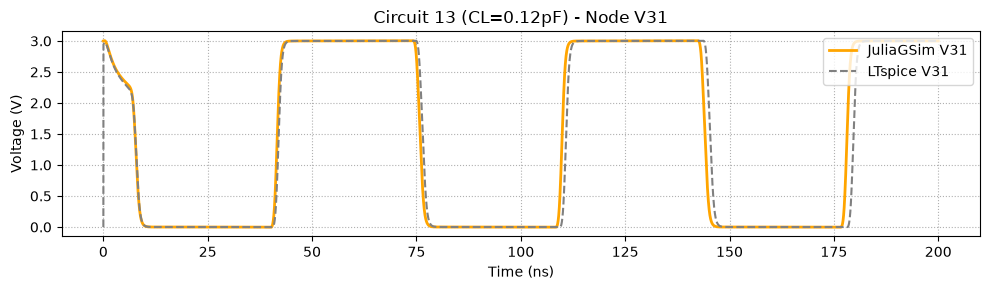

------------------------------------------------------------
 Worst Case #14 | Circuit 14 | CL = 0.117 pF | Freq Err = 0.88 %
 JuliaGSim Freq: 14.49 MHz | LTspice Freq: 14.37 MHz


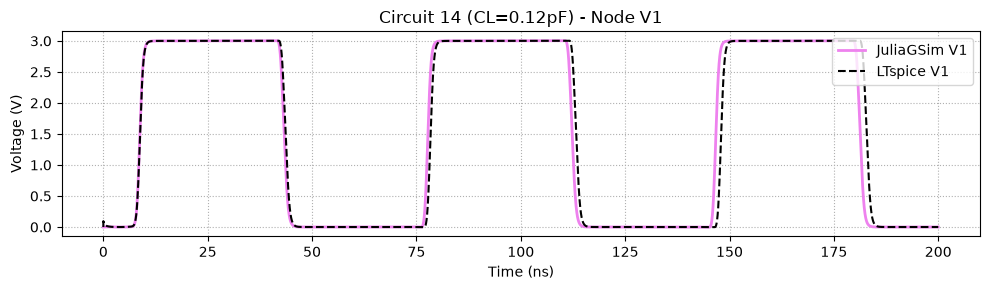

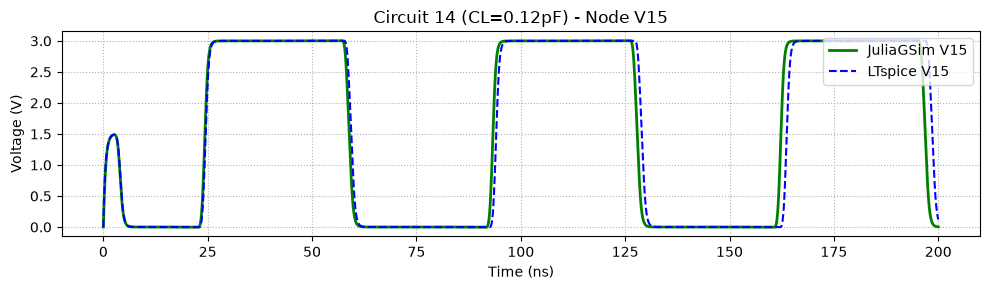

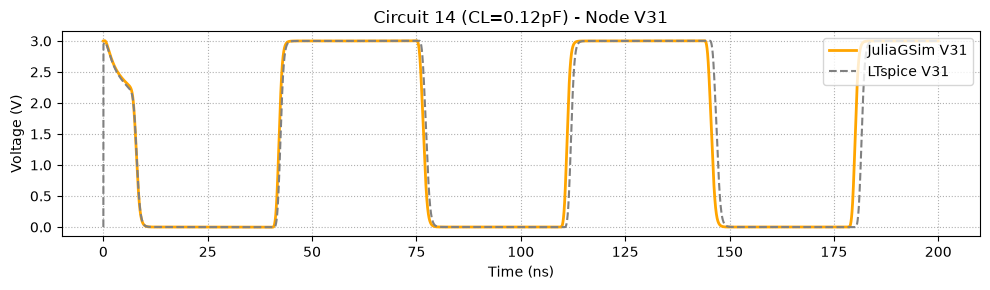

------------------------------------------------------------
 Worst Case #15 | Circuit 15 | CL = 0.119 pF | Freq Err = 0.87 %
 JuliaGSim Freq: 14.34 MHz | LTspice Freq: 14.21 MHz


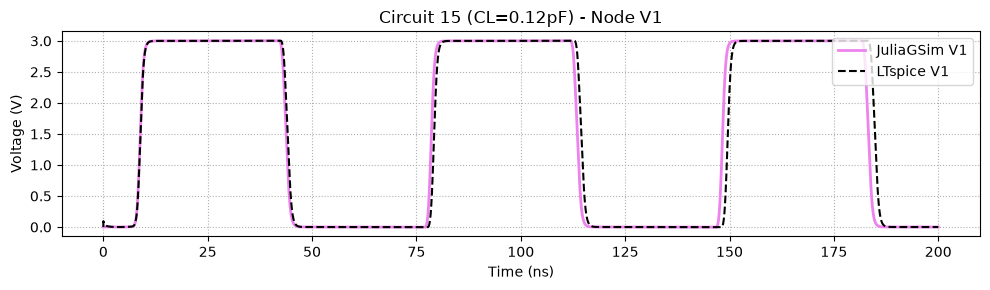

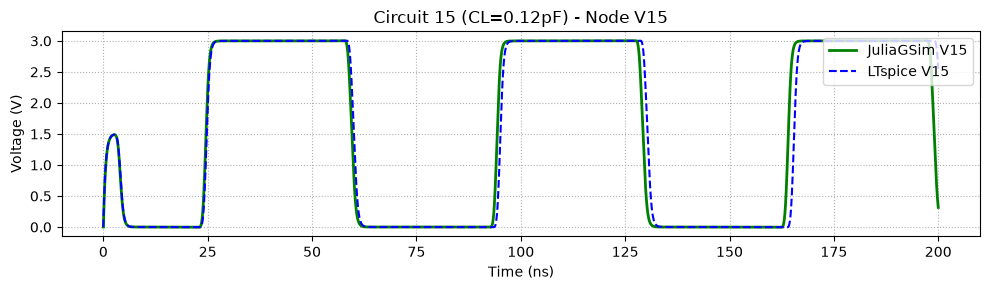

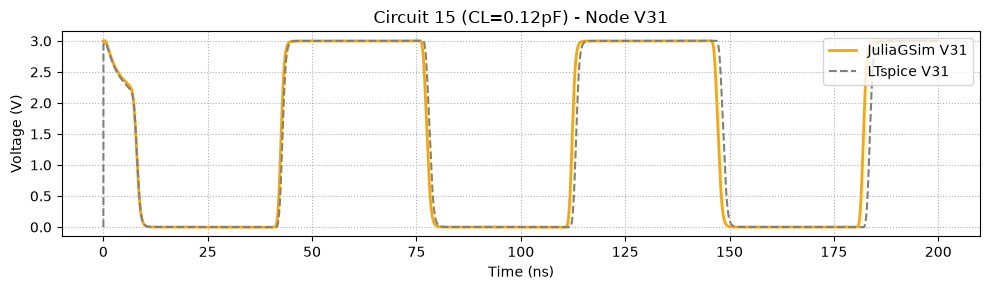

------------------------------------------------------------
 Worst Case #16 | Circuit 16 | CL = 0.120 pF | Freq Err = 0.86 %
 JuliaGSim Freq: 14.18 MHz | LTspice Freq: 14.06 MHz


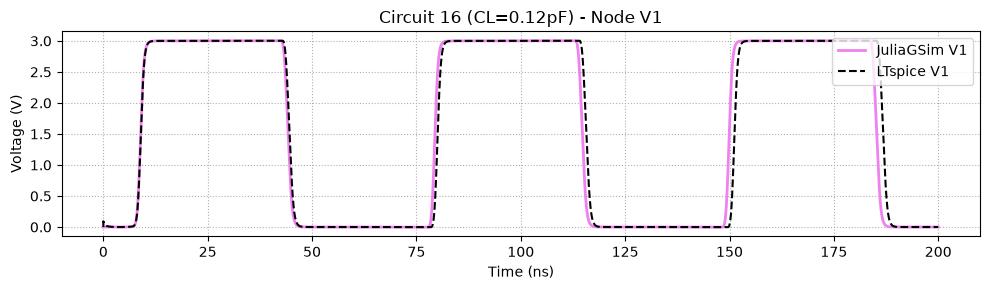

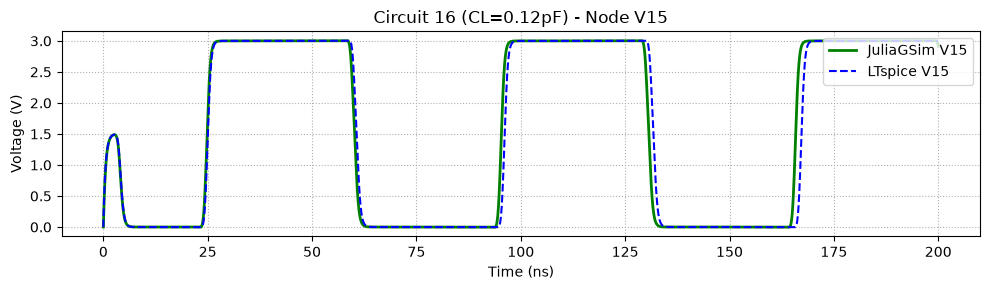

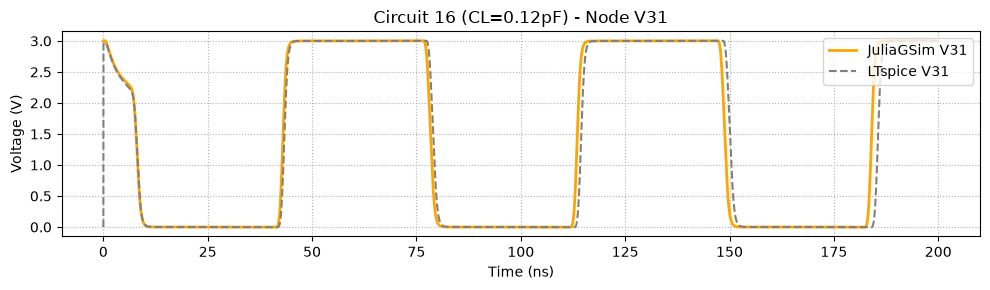

------------------------------------------------------------
 Worst Case #17 | Circuit 17 | CL = 0.121 pF | Freq Err = 0.85 %
 JuliaGSim Freq: 14.04 MHz | LTspice Freq: 13.92 MHz


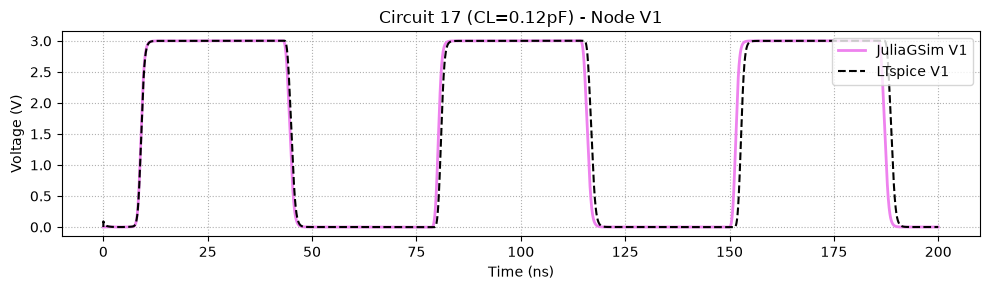

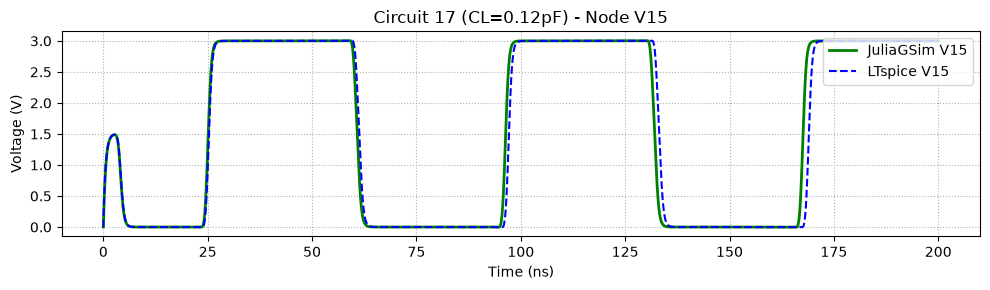

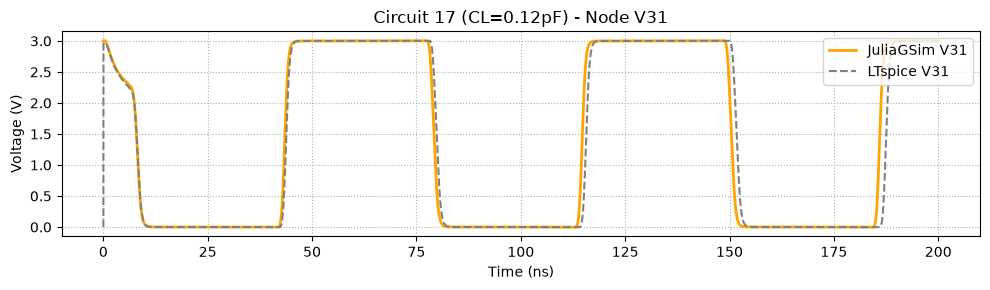

------------------------------------------------------------
 Worst Case #18 | Circuit 18 | CL = 0.123 pF | Freq Err = 0.84 %
 JuliaGSim Freq: 13.89 MHz | LTspice Freq: 13.77 MHz


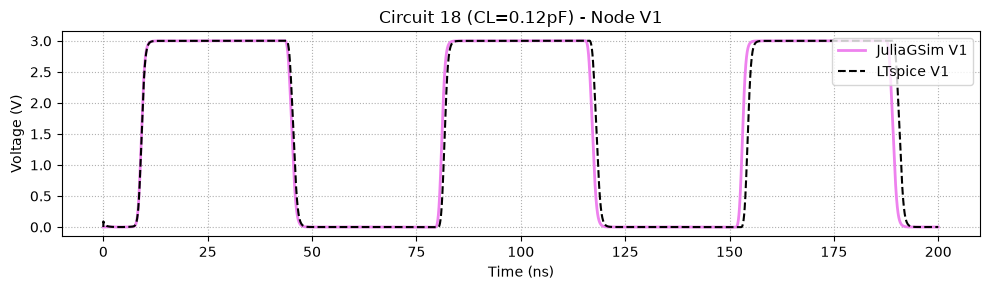

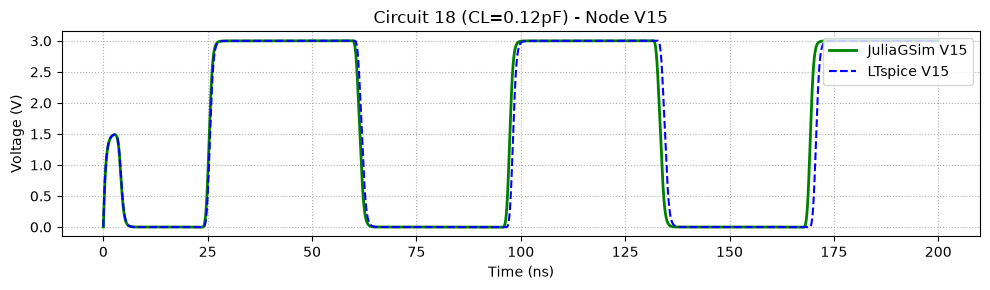

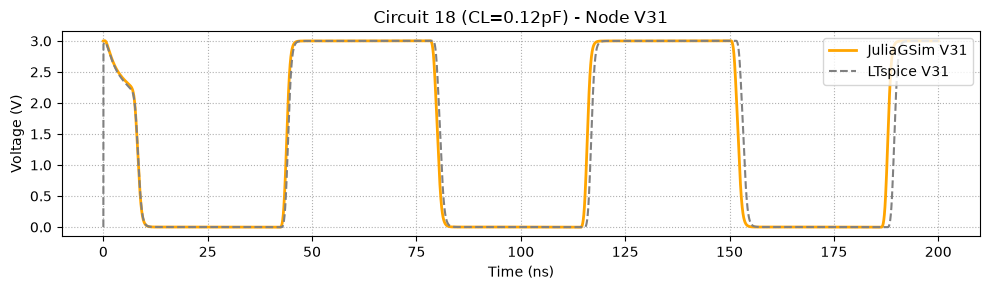

------------------------------------------------------------
 Worst Case #19 | Circuit 19 | CL = 0.124 pF | Freq Err = 0.83 %
 JuliaGSim Freq: 13.75 MHz | LTspice Freq: 13.63 MHz


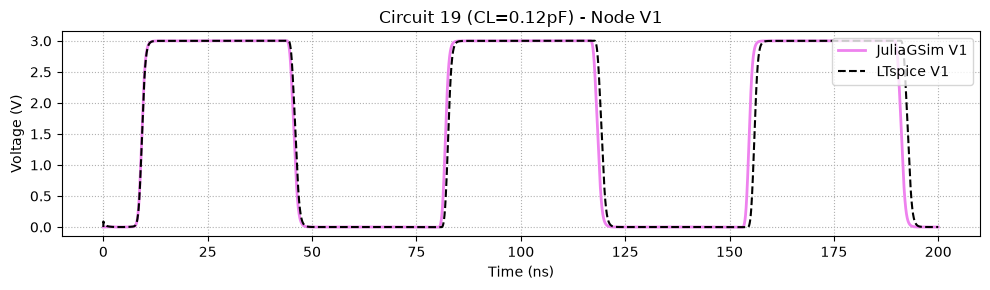

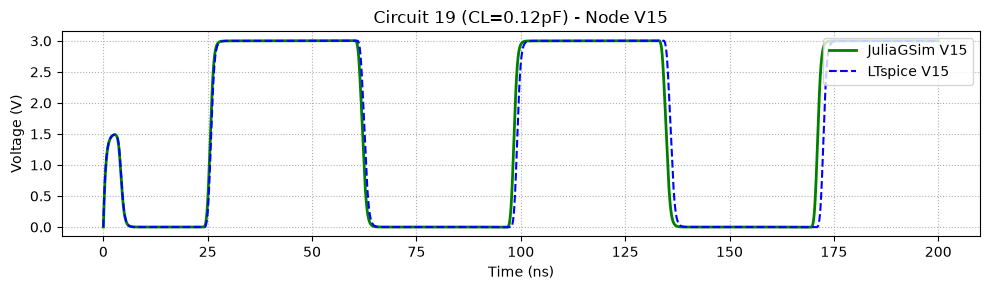

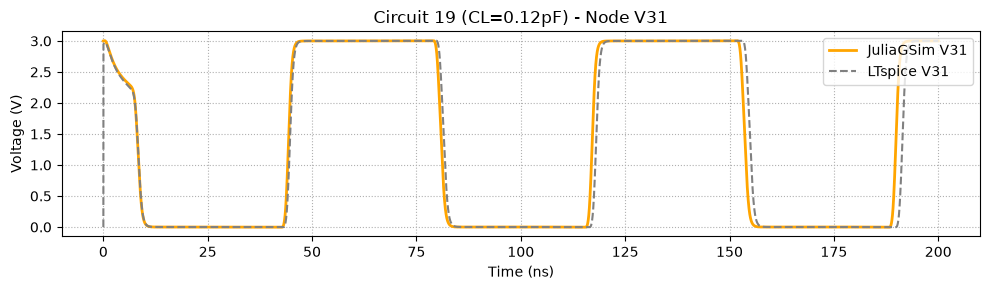

------------------------------------------------------------
 Worst Case #20 | Circuit 20 | CL = 0.125 pF | Freq Err = 0.82 %
 JuliaGSim Freq: 13.60 MHz | LTspice Freq: 13.49 MHz


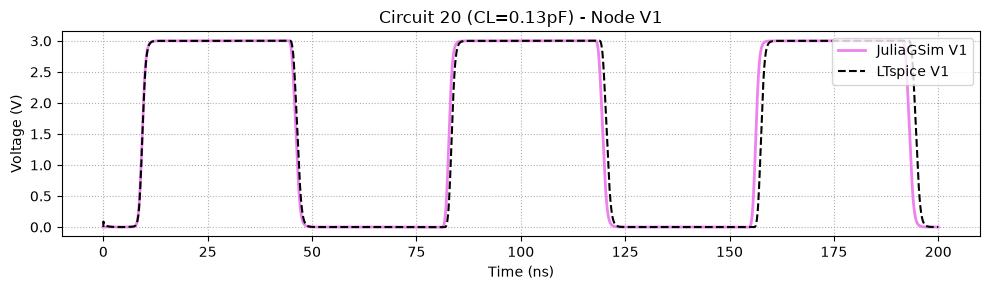

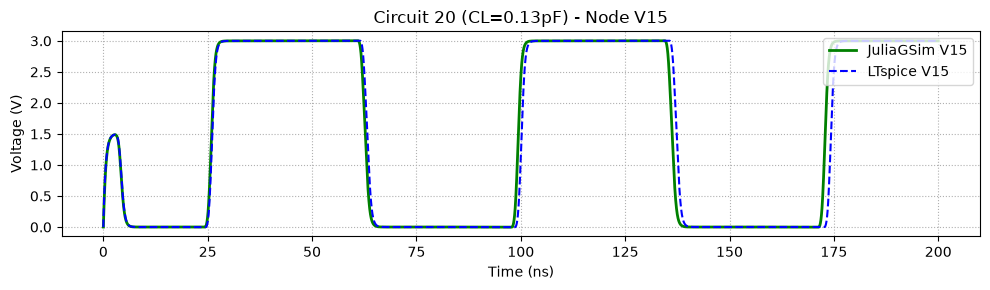

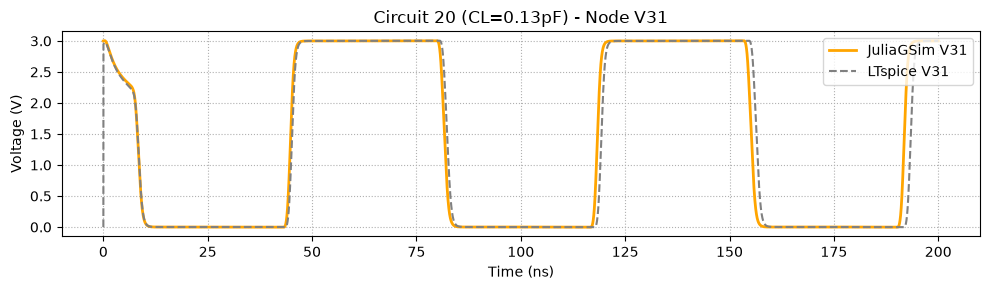

------------------------------------------------------------


In [1]:
# 0. Set Python Environment
ENV["JULIA_PYTHONCALL_EXE"] = "C:\\Users\\mohamed\\.conda\\envs\\Thesis_Optimizer_Sandbox_Copy\\python.exe"

using Printf
using StaticArrays
using PythonCall
using Random
using JLD2
using Interpolations
using Statistics
using Base.Threads

# ==============================================================================
# 1. Call the Surrogate definitions and the simulator Engine
# ==============================================================================
# 1. Load technology model definitions
include("C:\\Users\\mohamed\\Desktop\\ML\\CAD_projects\\Netlists\\GF_180nm_tech_work\\project\\New_Sim_tests\\Allah_help_me2\\Allah_Save_me\\New folder\\system\\Julia_GSim\\Vector_Sim_Engine\\Surrogate_definitions.jl")

# 2. Load the Engine (choose Static for small circuits or Sparse for large circuits)
include("C:\\Users\\mohamed\\Desktop\\ML\\CAD_projects\\Netlists\\GF_180nm_tech_work\\project\\New_Sim_tests\\Allah_help_me2\\Allah_Save_me\\New folder\\system\\Julia_GSim\\Vector_Sim_Engine\\Sparse_Sim.jl")


# ==============================================================================
# 2. LTSPICE VERIFICATION GROUND TRUTH (31-STAGE)
# ==============================================================================
g = pydict()
pyexec(raw"""
import os, subprocess, numpy as np
from PyLTSpice import RawRead

def run_ltspice_ring31_tran(L_val, mn, mp, CL, BASE_DIR='.'):
    os.makedirs(BASE_DIR, exist_ok=True)
    LTSPICE_PATH = r"C:\Users\Mohamed\AppData\Local\Programs\ADI\LTspice\LTspice.exe"
    
    netlist = []
    netlist.append("* 31-Stage CMOS Ring Oscillator (VCO)")
    netlist.append(".inc cmos_tt.txt")
    netlist.append(".op")
    netlist.append(".tran 0 200n 0 10p uic")
    netlist.append(".options plotwinsize=0")
    netlist.append("V0 vdd 0 3")
    
    # Generate 31 cascaded stages dynamically
    for i in range(1, 32):
        in_node = f"V{31 if i==1 else i-1}"
        out_node = f"V{i}"
        netlist.append(f"* STAGE {i}")
        netlist.append(f"M{2*i-1} {out_node} {in_node} vdd vdd pmos_3p3 w=0.5u l={L_val} m={mp}")
        netlist.append(f"M{2*i} {out_node} {in_node} 0 0 nmos_3p3 w=0.5u l={L_val} m={mn}")
        
        # Inject the kickstart initial condition ONLY on the last node
        if i == 31:
            netlist.append(f"C{i} {out_node} 0 {CL} ic=3")
        else:
            netlist.append(f"C{i} {out_node} 0 {CL}")
            
    netlist.append(".model NMOS NMOS")
    netlist.append(".model PMOS PMOS")
    netlist.append(f".lib {os.path.join(os.environ.get('LOCALAPPDATA', ''), 'LTspice', 'lib', 'cmp', 'standard.mos')}")
    
    # Measure frequency off Node V1
    netlist.append(".meas tran t_v1_1 TRIG v(V1) VAL=1.5 RISE=1")
    netlist.append(".meas tran t_v1_2 TRIG v(V1) VAL=1.5 RISE=2")
    netlist.append(".meas tran f_osc param abs(1/(t_v1_2-t_v1_1))")
    netlist.append(".end")
    
    netlist_str = "\n".join(netlist)
    sp_path = os.path.join(BASE_DIR, "tran_test_ring31.sp")
    raw_path = os.path.join(BASE_DIR, "tran_test_ring31.raw")
    log_path = os.path.join(BASE_DIR, "tran_test_ring31.log")
    
    if os.path.exists(raw_path):
        os.remove(raw_path)
        
    with open(sp_path, 'w', encoding='utf-8') as f: 
        f.write(netlist_str)
        
    subprocess.run([LTSPICE_PATH, "-b", "-run", sp_path], cwd=BASE_DIR, capture_output=True)
    raw = RawRead(raw_path)
    t = raw.get_trace("time").get_wave(0)
    
    # Extract 3 nodes across the ring
    v1 = raw.get_trace("V(v1)").get_wave(0)
    v15 = raw.get_trace("V(v15)").get_wave(0)
    v31 = raw.get_trace("V(v31)").get_wave(0)
    
    f_osc = 0.0
    if os.path.exists(log_path):
        with open(log_path, 'r', encoding='utf-8') as f:
            for line in f:
                if line.strip().startswith('f_osc:'):
                    try: f_osc = float(line.split('=')[1].strip())
                    except: pass
    return t, v1, v15, v31, f_osc
""", g)
run_ltspice_ring31_tran = g["run_ltspice_ring31_tran"]

# ==============================================================================
# 3. CIRCUIT DEFINITIONS & 300-BATCH SETUP
# ==============================================================================
struct CircuitParams
    L_val::Float64
    mp::Float64
    mn::Float64
    CL::Float64
end

N = 300
CL_arr = range(0.1e-12, 0.5e-12, length=N)

circuits = Vector{CircuitParams}(undef, N)
for i in 1:N
    circuits[i] = CircuitParams(300e-9, 3.33, 1.0, CL_arr[i])
end

println("\n====================================================================")
println(" TRANSIENT BATCH EVALUATION: $(N) CIRCUITS (31-STAGE RING OSCILLATOR)")
println("====================================================================")

sim_tran = JuliaGSim(surrogate_model)
add_vsource!(sim_tran, "V0", "vdd", "0", 3.0)

# Build the 31 stages dynamically in Julia
for i in 1:31
    in_node = i == 1 ? "V31" : "V$(i-1)"
    out_node = "V$i"
    
    add_pmos!(sim_tran, "MP$i", d=out_node, g=in_node, s="vdd", b="vdd", M=:mp, L=:L_val)
    add_nmos!(sim_tran, "MN$i", d=out_node, g=in_node, s="0", b="0", M=:mn, L=:L_val)
    
    if i == 31
        add_cap!(sim_tran, "C$i", out_node, "0", :CL; ic=3.0)
    else
        add_cap!(sim_tran, "C$i", out_node, "0", :CL)
    end
end

compile!(sim_tran)

BASE_DIR = pwd()

# ==============================================================================
# 4. RUN JULIAGSIM (ALWAYS RUNS FRESH & OVERWRITES CACHE)
# ==============================================================================
println("\n>>> Running $(N)-Batch Transient Solves on $(nthreads()) Julia Threads (Gear Method)...")

t_stop = 200e-9
dt_init = 10e-12
dt_max = 10e-12 

results_x_hist = Vector{Matrix{Float64}}(undef, N)
results_t_hist = Vector{Vector{Float64}}(undef, N)

start_time = time()
@threads for i in 1:N
    t_hist, x_hist = solve_tran(sim_tran, circuits[i], t_stop, dt_init, uic=true, dt_max=dt_max, method=:gear)
    results_x_hist[i] = x_hist
    results_t_hist[i] = t_hist
end
total_time = time() - start_time

println("Julia $(N)-Circuit Transient Total Time: $(round(total_time, digits=4)) s")

# Save/overwrite fresh Julia simulation results to disk
julia_cache_file = joinpath(BASE_DIR, "julia_ring31_cache_$(N).jld2")
@save julia_cache_file results_t_hist results_x_hist total_time
println("    Saved fresh Julia results to: $julia_cache_file")

idx_v1 = findfirst(==("V1"), sim_tran.unknown_nodes)
idx_v15 = findfirst(==("V15"), sim_tran.unknown_nodes)
idx_v31 = findfirst(==("V31"), sim_tran.unknown_nodes)

# ==============================================================================
# 5. RUN LTSPICE BASELINE (ALWAYS RUNS FRESH & OVERWRITES CACHE)
# ==============================================================================
println("\n>>> Running LTspice baseline (Sequential)...")

spice_times = Vector{Any}(undef, N)
spice_v1s   = Vector{Any}(undef, N)
spice_v15s  = Vector{Any}(undef, N)
spice_v31s  = Vector{Any}(undef, N)
spice_freqs = zeros(N)

start_spice = time()
for i in 1:N
    t_lt, v1_lt, v15_lt, v31_lt, f_osc_lt = run_ltspice_ring31_tran(
        circuits[i].L_val, circuits[i].mn, circuits[i].mp, circuits[i].CL, BASE_DIR
    )
    spice_times[i] = pyconvert(Array, t_lt)
    spice_v1s[i]   = pyconvert(Array, v1_lt)
    spice_v15s[i]  = pyconvert(Array, v15_lt)
    spice_v31s[i]  = pyconvert(Array, v31_lt)
    spice_freqs[i] = pyconvert(Float64, f_osc_lt)
    if i % 50 == 0; println("    LTspice progress: $i/$N circuits done..."); end
end
spice_time = time() - start_spice

println("LTspice Total Time: $(round(spice_time, digits=4)) s")

# Save/overwrite fresh LTspice simulation results to disk
spice_cache_file = joinpath(BASE_DIR, "ltspice_ring31_cache_$(N).jld2")
@save spice_cache_file spice_times spice_v1s spice_v15s spice_v31s spice_freqs spice_time
println("    Saved fresh LTspice results to: $spice_cache_file")

speedup = spice_time / total_time
println("\n======================================================================")
println(" 🚀 TRANSIENT PERFORMANCE SUMMARY (31-STAGE)")
println("======================================================================")
@printf(" JuliaGSim Time : %.3f seconds\n", total_time)
@printf(" LTspice Time   : %.3f seconds\n", spice_time)
@printf(" Speedup Factor : %.2fx faster than LTspice!\n", speedup)
println("======================================================================\n")

# ==============================================================================
# 6. FREQUENCY EXTRACTION & FULL 300-CIRCUIT COMPARISON TABLE
# ==============================================================================
jl_freqs = zeros(N)
for i in 1:N
    times = results_t_hist[i]
    v1_arr = results_x_hist[i][idx_v1, :]
    
    t_v1_1, t_v1_2 = 0.0, 0.0
    rise_count = 0
    for j in 2:length(times)
        if v1_arr[j-1] < 1.5 && v1_arr[j] >= 1.5
            # Precise linear interpolation of 1.5V crossing to match SPICE
            t_cross = times[j-1] + (1.5 - v1_arr[j-1]) * (times[j] - times[j-1]) / (v1_arr[j] - v1_arr[j-1])
            rise_count += 1
            if rise_count == 1
                t_v1_1 = t_cross
            elseif rise_count == 2
                t_v1_2 = t_cross
                break
            end
        end
    end
    jl_freqs[i] = (rise_count >= 2) ? abs(1.0 / (t_v1_2 - t_v1_1)) : 0.0
end

println("==========================================================================================")
println(" DETAILED CIRCUIT RESULTS (FREQUENCY COMPARISON)")
println("==========================================================================================\n")
@printf("%-10s | %-12s | %-15s | %-15s | %-15s\n", "Circuit", "CL (pF)", "Julia Freq", "LTspice Freq", "Error (%)")
println(repeat("-", 75))

freq_errors = zeros(N)
for i in 1:N
    err = spice_freqs[i] > 0 ? abs(jl_freqs[i] - spice_freqs[i]) / spice_freqs[i] * 100 : 0.0
    freq_errors[i] = err
    @printf("%-10d | %-12.3f | %-11.2f MHz | %-11.2f MHz | %-11.2f %%\n", i, circuits[i].CL * 1e12, jl_freqs[i] / 1e6, spice_freqs[i] / 1e6, err)
end
println()

println("======================================================================")
println(" OVERALL ACCURACY STATISTICAL SUMMARY ($(N) CIRCUITS)")
println("======================================================================")
@printf(" Max Frequency Error     : %.2f %%\n", maximum(freq_errors))
@printf(" Mean Frequency Error    : %.2f %%\n", mean(freq_errors))
@printf(" Min Oscillation Freq    : %.2f MHz\n", minimum(jl_freqs)/1e6)
@printf(" Max Oscillation Freq    : %.2f MHz\n", maximum(jl_freqs)/1e6)
println("======================================================================\n")

# ==============================================================================
# 7. VCO TUNING CHARACTERISTIC: fosc vs. CL (RED for Julia, BLUE for LTspice)
# ==============================================================================
plt = pyimport("matplotlib.pyplot")

fig_tune = plt.figure(figsize=(10, 5))
CL_vals_pF = [circuits[i].CL * 1e12 for i in 1:N]

plt.plot(CL_vals_pF, jl_freqs ./ 1e6, color="red", linewidth=2.5, label="JuliaGSim")
plt.plot(CL_vals_pF, spice_freqs ./ 1e6, color="blue", linestyle="--", linewidth=2.0, label="LTspice")
plt.title("31-Stage Ring Oscillator Tuning: Frequency vs. Load Capacitance ($(N) Circuits)", fontsize=12)
plt.xlabel("Load Capacitance CL (pF)", fontsize=11)
plt.ylabel("Oscillation Frequency (MHz)", fontsize=11)
plt.legend(loc="upper right", fontsize=11)
plt.grid(true, which="both", ls=":")
plt.tight_layout()

buf_tune = pyimport("io").BytesIO()
fig_tune.savefig(buf_tune, format="png", bbox_inches="tight")
display(MIME("image/png"), pyconvert(Vector{UInt8}, buf_tune.getvalue()))
plt.close(fig_tune)
println()

# ==============================================================================
# 8. WAVEFORM PLOTS: TOP 20 CIRCUITS WITH HIGHEST MISMATCH (60 IMAGES TOTAL)
# ==============================================================================
worst_order = sortperm(freq_errors, rev=true)
worst_20 = worst_order[1:min(20, N)]

println("======================================================================")
println(" WAVEFORM PLOTS: TOP 20 CIRCUITS WITH HIGHEST FREQUENCY MISMATCH")
println(" (3 SEPARATE FIGURES PER CIRCUIT: V1, V15, V31 -> TOTAL 60 FIGURES)")
println("======================================================================\n")

for (rank, i) in enumerate(worst_20)
    times_jl_arr = results_t_hist[i]
    v1_arr = results_x_hist[i][idx_v1, :]
    v15_arr = results_x_hist[i][idx_v15, :]
    v31_arr = results_x_hist[i][idx_v31, :]

    println(repeat("=", 75))
    @printf(" Worst Case #%d | Circuit %d | CL = %.3f pF | Freq Err = %.2f %%\n", rank, i, circuits[i].CL * 1e12, freq_errors[i])
    @printf(" JuliaGSim Freq: %.2f MHz | LTspice Freq: %.2f MHz\n", jl_freqs[i]/1e6, spice_freqs[i]/1e6)
    println(repeat("=", 75))

    # PLOT 1: V1
    fig1 = plt.figure(figsize=(10, 3))
    plt.plot(times_jl_arr .* 1e9, v1_arr, color="violet", linewidth=2, label="JuliaGSim V1")
    plt.plot(spice_times[i] .* 1e9, spice_v1s[i], color="black", linestyle="--", label="LTspice V1")
    plt.title("Circuit $i (CL=$(round(circuits[i].CL*1e12, digits=2))pF) - Node V1")
    plt.xlabel("Time (ns)")
    plt.ylabel("Voltage (V)")
    plt.legend(loc="upper right")
    plt.grid(true, which="both", ls=":")
    plt.tight_layout()
    buf1 = pyimport("io").BytesIO()
    fig1.savefig(buf1, format="png", bbox_inches="tight")
    display(MIME("image/png"), pyconvert(Vector{UInt8}, buf1.getvalue()))
    plt.close(fig1)

    # PLOT 2: V15
    fig2 = plt.figure(figsize=(10, 3))
    plt.plot(times_jl_arr .* 1e9, v15_arr, color="green", linewidth=2, label="JuliaGSim V15")
    plt.plot(spice_times[i] .* 1e9, spice_v15s[i], color="blue", linestyle="--", label="LTspice V15")
    plt.title("Circuit $i (CL=$(round(circuits[i].CL*1e12, digits=2))pF) - Node V15")
    plt.xlabel("Time (ns)")
    plt.ylabel("Voltage (V)")
    plt.legend(loc="upper right")
    plt.grid(true, which="both", ls=":")
    plt.tight_layout()
    buf2 = pyimport("io").BytesIO()
    fig2.savefig(buf2, format="png", bbox_inches="tight")
    display(MIME("image/png"), pyconvert(Vector{UInt8}, buf2.getvalue()))
    plt.close(fig2)

    # PLOT 3: V31
    fig3 = plt.figure(figsize=(10, 3))
    plt.plot(times_jl_arr .* 1e9, v31_arr, color="orange", linewidth=2, label="JuliaGSim V31")
    plt.plot(spice_times[i] .* 1e9, spice_v31s[i], color="grey", linestyle="--", label="LTspice V31")
    plt.title("Circuit $i (CL=$(round(circuits[i].CL*1e12, digits=2))pF) - Node V31")
    plt.xlabel("Time (ns)")
    plt.ylabel("Voltage (V)")
    plt.legend(loc="upper right")
    plt.grid(true, which="both", ls=":")
    plt.tight_layout()
    buf3 = pyimport("io").BytesIO()
    fig3.savefig(buf3, format="png", bbox_inches="tight")
    display(MIME("image/png"), pyconvert(Vector{UInt8}, buf3.getvalue()))
    plt.close(fig3)

    println(repeat("-", 60))
end
